## <center>**KECERDASAN ARTIFISIAL UNTUK GEOFISIKA**</center>
### <center>**Prompt AI untuk Penyelesaian Masalah Geofisika**</center>
#### **NAMA**   : **SAMIDA DANDA**
#### **NIM**    : **H061231089**
#### **KELAS**  : **B**
<hr>

### ***PROMPT 1: PEMETAAN KEKERINGAN MENGGUNAKAN TVDI***

#### ***Judul: Pemetaan Risiko Kekeringan Menggunakan Temperature Vegetation Dryness Index (TVDI)***

Bertindaklah sebagai ahli penginderaan jauh dan geofisika lingkungan serta dosen pembimbing praktikum Geofisika yang menguasai pengolahan citra satelit, NDVI, LST, TVDI, dan pemetaan kekeringan. Lakukan analisis tingkat kekeringan menggunakan metode TVDI berdasarkan hubungan NDVI dan LST, mulai dari pemeriksaan data, perhitungan NDVI dan LST, analisis hubungan NDVI–LST, penentuan dry edge dan wet edge, perhitungan TVDI, klasifikasi, hingga pemetaan dan interpretasi spasial.

Gunakan data citra dan informasi wilayah yang diberikan pengguna. Jelaskan proses dengan bahasa ilmiah yang sederhana untuk mahasiswa S1 Geofisika, jangan mengarang data atau hasil, dan nyatakan apabila terdapat data yang kurang. Sajikan hasil berupa tahapan pengolahan, rumus dan penjelasan parameter, peta TVDI, klasifikasi kekeringan, interpretasi spasial, dan kesimpulan. Periksa kembali kualitas data, rentang nilai NDVI–LST–TVDI, hasil klasifikasi, dan konsistensi interpretasi sebelum memberikan hasil akhir.


In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt


# ============================================================
# 1. PENGATURAN FOLDER DAN FILE
# ============================================================

BASE_DIR = Path(r"D:\ArcGIS\KKN Project").resolve().parent
DATA_DIR = BASE_DIR / "data"
OUT_DIR = BASE_DIR / "hasil_TVDI_Bantaeng"

OUT_DIR.mkdir(parents=True, exist_ok=True)

B4_FILE = DATA_DIR / (r"D:\ArcGIS\KKN Project\LC08_L2SP_114064_20250919_20250929_02_T1_SR_B4.TIF")
B5_FILE = DATA_DIR / (r"D:\ArcGIS\KKN Project\LC08_L2SP_114064_20250919_20250929_02_T1_SR_B5.TIF")
B10_FILE = DATA_DIR / (r"D:\ArcGIS\KKN Project\LC08_L2SP_114064_20250919_20250929_02_T1_ST_B10.TIF")

for file in [B4_FILE, B5_FILE, B10_FILE]:
    if not file.exists():
        raise FileNotFoundError(f"File tidak ditemukan: {file}")


# ============================================================
# 2. MEMBACA RASTER DAN MEMERIKSA KECocokan GRID
# ============================================================

with rasterio.open(B4_FILE) as src4, \
     rasterio.open(B5_FILE) as src5, \
     rasterio.open(B10_FILE) as src10:

    print("=== INFORMASI RASTER ===")
    print("CRS:", src4.crs)
    print("Ukuran:", src4.width, "x", src4.height)
    print("Resolusi:", src4.res)
    print("Bounds:", src4.bounds)

    if not (
        src4.crs == src5.crs == src10.crs
        and src4.transform == src5.transform == src10.transform
        and src4.width == src5.width == src10.width
        and src4.height == src5.height == src10.height
    ):
        raise ValueError(
            "Grid B4, B5, dan B10 tidak sama. "
            "Ketiga raster perlu diselaraskan terlebih dahulu."
        )

    b4_raw = src4.read(1).astype("float32")
    b5_raw = src5.read(1).astype("float32")
    b10_raw = src10.read(1).astype("float32")

    profile = src4.profile.copy()

    mask4 = src4.read_masks(1) > 0
    mask5 = src5.read_masks(1) > 0
    mask10 = src10.read_masks(1) > 0


# ============================================================
# 3. MASKING DATA TIDAK VALID
# ============================================================

valid = (
    mask4
    & mask5
    & mask10
    & np.isfinite(b4_raw)
    & np.isfinite(b5_raw)
    & np.isfinite(b10_raw)
    & (b4_raw > 0)
    & (b5_raw > 0)
    & (b10_raw > 0)
)

if valid.sum() == 0:
    raise ValueError(
        "Tidak ada piksel valid. Periksa nilai NoData dan file input."
    )


# ============================================================
# 4. SKALA REFLEKTANSI LANDSAT COLLECTION 2 LEVEL-2
# ============================================================

# Rumus resmi Surface Reflectance:
# SR = DN * 0.0000275 - 0.2

red = b4_raw * 0.0000275 - 0.2
nir = b5_raw * 0.0000275 - 0.2

den_ndvi = nir + red

valid_ndvi = valid & (np.abs(den_ndvi) > 1e-6)

ndvi = np.full(b4_raw.shape, np.nan, dtype="float32")

ndvi[valid_ndvi] = (
    (nir[valid_ndvi] - red[valid_ndvi])
    / den_ndvi[valid_ndvi]
)

# Batasi nilai NDVI yang valid secara fisik
valid_ndvi &= (ndvi >= -1) & (ndvi <= 1)
ndvi[~valid_ndvi] = np.nan


# ============================================================
# 5. KONVERSI ST_B10 MENJADI LST CELSIUS
# ============================================================

# Landsat Collection 2 Level-2 Surface Temperature:
# Kelvin = DN * 0.00341802 + 149.0
# Celsius = Kelvin - 273.15

lst_kelvin = b10_raw * 0.00341802 + 149.0
lst_c = lst_kelvin - 273.15

# Pemeriksaan rentang suhu fisik secara konservatif
valid_lst = (
    valid
    & np.isfinite(lst_c)
    & (lst_c > -50)
    & (lst_c < 100)
)

lst_c = lst_c.astype("float32")
lst_c[~valid_lst] = np.nan

# Samakan mask NDVI dan LST untuk analisis TVDI
joint_valid = valid_ndvi & valid_lst
ndvi[~joint_valid] = np.nan
lst_c[~joint_valid] = np.nan

if joint_valid.sum() == 0:
    raise ValueError("Tidak ada piksel NDVI dan LST yang sama-sama valid.")

print("\nJumlah piksel valid:", int(joint_valid.sum()))


# ============================================================
# 6. MENYIAPKAN DATA NDVI-LST
# ============================================================

df = pd.DataFrame({
    "NDVI": ndvi[joint_valid],
    "LST_C": lst_c[joint_valid],
})

df = df.replace([np.inf, -np.inf], np.nan).dropna()

df.to_csv(
    OUT_DIR / "sampel_NDVI_LST.csv",
    index=False
)

print("\nStatistik NDVI:")
print(df["NDVI"].describe())

print("\nStatistik LST (Celsius):")
print(df["LST_C"].describe())


# ============================================================
# 7. ESTIMASI WET EDGE DAN DRY EDGE
# ============================================================

# Bagi NDVI ke dalam bin 0.05.
# Wet edge: persentil 5 LST dalam setiap bin.
# Dry edge: persentil 95 LST dalam setiap bin.

BIN_WIDTH = 0.05
MIN_PIXELS_PER_BIN = 30

bin_edges = np.arange(-1.0, 1.0001, BIN_WIDTH)

df["bin"] = pd.cut(
    df["NDVI"],
    bins=bin_edges,
    include_lowest=True,
    right=False
)

edge_table = (
    df.groupby("bin", observed=True)
    .agg(
        NDVI_mean=("NDVI", "mean"),
        LST_p5=("LST_C", lambda x: x.quantile(0.05)),
        LST_p95=("LST_C", lambda x: x.quantile(0.95)),
        N=("LST_C", "count"),
    )
    .reset_index(drop=True)
)

edge_table = edge_table[
    (edge_table["N"] >= MIN_PIXELS_PER_BIN)
].dropna()

if len(edge_table) < 3:
    raise ValueError(
        "Kurang dari 3 bin NDVI memiliki sampel yang cukup. "
        "Wet edge dan dry edge belum dapat diestimasi secara andal."
    )

# Regresi linear untuk masing-masing edge
wet_coef = np.polyfit(
    edge_table["NDVI_mean"],
    edge_table["LST_p5"],
    1
)

dry_coef = np.polyfit(
    edge_table["NDVI_mean"],
    edge_table["LST_p95"],
    1
)

edge_table["wet_fit"] = np.polyval(
    wet_coef, edge_table["NDVI_mean"]
)

edge_table["dry_fit"] = np.polyval(
    dry_coef, edge_table["NDVI_mean"]
)

edge_table.to_csv(
    OUT_DIR / "tabel_wet_dry_edge.csv",
    index=False
)

print("\nPersamaan wet edge:")
print(f"LST_wet = {wet_coef[0]:.5f} * NDVI + {wet_coef[1]:.5f}")

print("\nPersamaan dry edge:")
print(f"LST_dry = {dry_coef[0]:.5f} * NDVI + {dry_coef[1]:.5f}")

print("Jumlah bin yang digunakan:", len(edge_table))


# ============================================================
# 8. GRAFIK HUBUNGAN NDVI-LST
# ============================================================

plt.figure(figsize=(10, 7))

plt.scatter(
    df["NDVI"],
    df["LST_C"],
    s=3,
    alpha=0.2,
    label="Piksel valid"
)

x = np.linspace(
    edge_table["NDVI_mean"].min(),
    edge_table["NDVI_mean"].max(),
    200
)

plt.plot(
    x,
    np.polyval(wet_coef, x),
    linewidth=2,
    label="Wet edge (P5)"
)

plt.plot(
    x,
    np.polyval(dry_coef, x),
    linewidth=2,
    label="Dry edge (P95)"
)

plt.xlabel("NDVI")
plt.ylabel("LST (°C)")
plt.title("Hubungan NDVI-LST Kabupaten Bantaeng")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(OUT_DIR / "grafik_NDVI_LST.png", dpi=300)
plt.close()


# ============================================================
# 9. MENGHITUNG TVDI
# ============================================================

wet_image = (
    wet_coef[0] * ndvi + wet_coef[1]
)

dry_image = (
    dry_coef[0] * ndvi + dry_coef[1]
)

denominator = dry_image - wet_image

# Edge harus terurut: dry edge > wet edge
valid_tvdi = (
    joint_valid
    & np.isfinite(denominator)
    & (denominator > 0)
)

tvdi = np.full(ndvi.shape, np.nan, dtype="float32")

tvdi[valid_tvdi] = (
    (lst_c[valid_tvdi] - wet_image[valid_tvdi])
    / denominator[valid_tvdi]
)

# Nilai mentah disimpan agar hasil di luar 0-1 tetap bisa dievaluasi
tvdi_raw = tvdi.copy()

# TVDI untuk pemetaan diklip ke 0-1
tvdi = np.clip(tvdi, 0, 1)


# ============================================================
# 10. KLASIFIKASI TVDI MENJADI 5 KELAS
# ============================================================

# 0: Sangat basah / tidak kering
# 1: Basah
# 2: Sedang
# 3: Kering
# 4: Sangat kering

classes = np.full(tvdi.shape, -1, dtype="int8")

classes[valid_tvdi & (tvdi < 0.2)] = 0
classes[valid_tvdi & (tvdi >= 0.2) & (tvdi < 0.4)] = 1
classes[valid_tvdi & (tvdi >= 0.4) & (tvdi < 0.6)] = 2
classes[valid_tvdi & (tvdi >= 0.6) & (tvdi < 0.8)] = 3
classes[valid_tvdi & (tvdi >= 0.8)] = 4


# ============================================================
# 11. MENYIMPAN GEOTIFF
# ============================================================

def save_raster(filename, array, dtype="float32", nodata=-9999):
    """Menyimpan raster dengan metadata spasial dari Band 4."""

    out_profile = profile.copy()
    out_profile.update(
        driver="GTiff",
        count=1,
        dtype=dtype,
        nodata=nodata,
        compress="lzw",
    )

    output = np.asarray(array).copy()
    output[~np.isfinite(output)] = nodata

    with rasterio.open(OUT_DIR / filename, "w", **out_profile) as dst:
        dst.write(output.astype(dtype), 1)

    print("Tersimpan:", OUT_DIR / filename)


save_raster("NDVI_Bantaeng.tif", ndvi)
save_raster("LST_Celsius_Bantaeng.tif", lst_c)
save_raster("TVDI_raw_Bantaeng.tif", tvdi_raw)
save_raster("TVDI_Bantaeng.tif", tvdi)
save_raster(
    "Kelas_TVDI_Bantaeng.tif",
    classes,
    dtype="int16",
    nodata=-1,
)


# ============================================================
# 12. STATISTIK LUAS PER KELAS
# ============================================================

# Luas piksel dalam km2 dihitung dari transformasi raster.
# Untuk UTM, satuan koordinat adalah meter.

pixel_area_km2 = abs(
    profile["transform"].a * profile["transform"].e
    - profile["transform"].b * profile["transform"].d
) / 1_000_000

class_names = {
    0: "Sangat basah / tidak kering",
    1: "Basah",
    2: "Sedang",
    3: "Kering",
    4: "Sangat kering",
}

rows = []

for class_id, class_name in class_names.items():
    pixel_count = int(np.sum(classes == class_id))
    area_km2 = pixel_count * pixel_area_km2

    rows.append({
        "kelas": class_id,
        "kategori": class_name,
        "jumlah_piksel": pixel_count,
        "luas_km2": area_km2,
    })

area_df = pd.DataFrame(rows)
total_area = area_df["luas_km2"].sum()

area_df["persentase"] = np.where(
    total_area > 0,
    area_df["luas_km2"] / total_area * 100,
    0,
)

area_df.to_csv(
    OUT_DIR / "luas_kelas_TVDI.csv",
    index=False
)

print("\n=== LUAS KELAS TVDI ===")
print(area_df.to_string(index=False))


# ============================================================
# 13. VISUALISASI RASTER
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

im1 = axes[0].imshow(ndvi, vmin=-1, vmax=1, cmap="RdYlGn")
axes[0].set_title("NDVI")
fig.colorbar(im1, ax=axes[0], shrink=0.75)

im2 = axes[1].imshow(lst_c, cmap="inferno")
axes[1].set_title("LST (°C)")
fig.colorbar(im2, ax=axes[1], shrink=0.75)

im3 = axes[2].imshow(tvdi, vmin=0, vmax=1, cmap="YlOrRd")
axes[2].set_title("TVDI")
fig.colorbar(im3, ax=axes[2], shrink=0.75)

for ax in axes:
    ax.axis("off")

plt.suptitle("Analisis TVDI - Kabupaten Bantaeng")
plt.tight_layout()
plt.savefig(
    OUT_DIR / "peta_ringkasan_TVDI.png",
    dpi=300,
    bbox_inches="tight"
)
plt.close()

print("\n===================================")
print("PENGOLAHAN SELESAI")
print("Folder hasil:", OUT_DIR.resolve())
print("===================================")


=== INFORMASI RASTER ===
CRS: EPSG:32650
Ukuran: 7631 x 7771
Resolusi: (30.0, 30.0)
Bounds: BoundingBox(left=671685.0, bottom=-757215.0, right=900615.0, top=-524085.0)

Jumlah piksel valid: 36336360

Statistik NDVI:
count    3.633636e+07
mean     3.023940e-01
std      3.067287e-01
min     -9.997906e-01
25%      1.604025e-01
50%      2.432139e-01
75%      4.610128e-01
max      9.999670e-01
Name: NDVI, dtype: float64

Statistik LST (Celsius):
count    3.633636e+07
mean     3.048434e+01
std      4.603656e+00
min      1.622894e+00
25%      2.877563e+01
50%      2.955154e+01
75%      3.012234e+01
max      7.023965e+01
Name: LST_C, dtype: float64

Persamaan wet edge:
LST_wet = -1.17911 * NDVI + 26.99606

Persamaan dry edge:
LST_dry = 5.66818 * NDVI + 35.60759
Jumlah bin yang digunakan: 40


Kolom tabel edge: ['NDVI_mean', 'LST_p5', 'LST_p95', 'N', 'wet_fit', 'dry_fit']


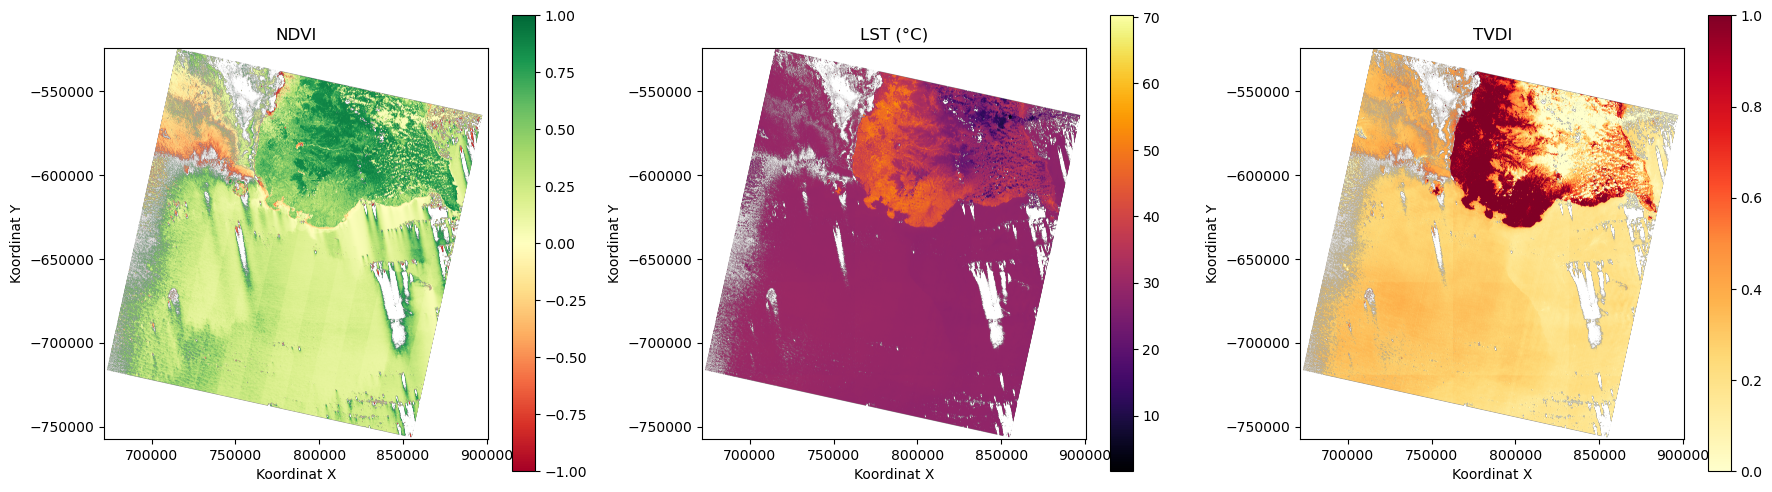

In [5]:

from pathlib import Path
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt

# ==================================================
# 1. LOKASI FOLDER
# ==================================================

BASE_DIR = Path(r"D:\ArcGIS")
OUT_DIR = BASE_DIR / "hasil_TVDI_Bantaeng"

# Cari file band asli
def cari_file(nama):
    hasil = list(BASE_DIR.rglob(nama))
    if not hasil:
        raise FileNotFoundError(
            f"File {nama} tidak ditemukan di {BASE_DIR}"
        )
    return hasil[0]

b4_file = cari_file(
    "LC08_L2SP_114064_20250919_20250929_02_T1_SR_B4.TIF"
)
b5_file = cari_file(
    "LC08_L2SP_114064_20250919_20250929_02_T1_SR_B5.TIF"
)
b10_file = cari_file(
    "LC08_L2SP_114064_20250919_20250929_02_T1_ST_B10.TIF"
)

# ==================================================
# 2. BACA BAND
# ==================================================

with rasterio.open(b4_file) as a, \
     rasterio.open(b5_file) as b, \
     rasterio.open(b10_file) as c:

    b4 = a.read(1).astype("float32")
    b5 = b.read(1).astype("float32")
    b10 = c.read(1).astype("float32")

    valid = (
        (a.read_masks(1) > 0)
        & (b.read_masks(1) > 0)
        & (c.read_masks(1) > 0)
        & (b4 > 0) & (b5 > 0) & (b10 > 0)
    )

    extent = (
        a.bounds.left, a.bounds.right,
        a.bounds.bottom, a.bounds.top
    )

# ==================================================
# 3. HITUNG NDVI DAN LST
# ==================================================

red = b4 * 0.0000275 - 0.2
nir = b5 * 0.0000275 - 0.2

ndvi = np.full(b4.shape, np.nan, dtype="float32")
den = nir + red

ok = valid & (np.abs(den) > 1e-6)
ndvi[ok] = (nir[ok] - red[ok]) / den[ok]
ndvi[(ndvi < -1) | (ndvi > 1)] = np.nan

lst = b10 * 0.00341802 + 149.0 - 273.15
lst = lst.astype("float32")
lst[~valid] = np.nan

joint = np.isfinite(ndvi) & np.isfinite(lst)
ndvi[~joint] = np.nan
lst[~joint] = np.nan

# ==================================================
# 4. HITUNG TVDI DARI KOEFISIEN EDGE DI CSV
# ==================================================

edge_file = OUT_DIR / "tabel_wet_dry_edge.csv"

if not edge_file.exists():
    raise FileNotFoundError(
        f"Tabel edge tidak ditemukan: {edge_file}"
    )

edges = pd.read_csv(edge_file)

# Periksa nama kolom pada CSV
print("Kolom tabel edge:", edges.columns.tolist())

# Hitung ulang regresi dari tabel edge
x = edges["NDVI_mean"].to_numpy()
wet = edges["LST_p5"].to_numpy()
dry = edges["LST_p95"].to_numpy()

wet_coef = np.polyfit(x, wet, 1)
dry_coef = np.polyfit(x, dry, 1)

wet_img = wet_coef[0] * ndvi + wet_coef[1]
dry_img = dry_coef[0] * ndvi + dry_coef[1]

den_tvdi = dry_img - wet_img
tvdi = np.full(ndvi.shape, np.nan, dtype="float32")

valid_tvdi = joint & (den_tvdi > 0)
tvdi[valid_tvdi] = np.clip(
    (lst[valid_tvdi] - wet_img[valid_tvdi])
    / den_tvdi[valid_tvdi],
    0, 1
)

# ==================================================
# 5. PLOT TIGA PETA
# ==================================================

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

items = [
    (ndvi, "NDVI", "RdYlGn", -1, 1),
    (lst, "LST (°C)", "inferno", None, None),
    (tvdi, "TVDI", "YlOrRd", 0, 1),
]

for ax, (data, title, cmap, vmin, vmax) in zip(axes, items):
    im = ax.imshow(
        data,
        extent=extent,
        origin="upper",
        cmap=cmap,
        vmin=vmin,
        vmax=vmax
    )
    ax.set_title(title)
    ax.set_xlabel("Koordinat X")
    ax.set_ylabel("Koordinat Y")
    fig.colorbar(im, ax=ax, shrink=0.8)

plt.tight_layout()
plt.show()



**Ketiga peta dapat diinterpretasikan sebagai :**

**NDVI** Area hijau pekat terkonsentrasi di bagian atas dan kanan Tutupan vegetasi relatif lebih baik

**LST**	Variasi suhu terlihat di bagian tengah hingga atas	Kondisi termal permukaan bervariasi

**TVDI** Area merah gelap menonjol di bagian tengah hingga atas	Kekeringan relatif lebih tinggi pada area tersebut
 Secara teoritis, vegetasi yang rapat cenderung memiliki NDVI tinggi dan dapat mengalami pendinginan melalui evapotranspirasi. Sebaliknya, area dengan vegetasi jarang dan suhu permukaan tinggi dapat menunjukkan TVDI lebih tinggi. Akan tetapi, pada gambar ini, hubungan tersebut tidak sepenuhnya dapat dipastikan hanya dari pola visual; diperlukan pemeriksaan nilai piksel dan grafik sebaran NDVI–LST untuk mengonfirmasi hubungan antarparameter.
pola spasial pada peta perlu diverifikasi sebelum dihubungkan dengan kondisi wilayah administratif tertentu. Peta yang ditampilkan masih berupa cakupan raster, dan belum menunjukkan batas administratif Kabupaten Bantaeng. Karena itu, interpretasi lokasi di atas mengacu pada posisi relatif dalam gambar, bukan pada kecamatan atau desa tertentu.

**Kesimpulan**
Berdasarkan hasil visualisasi NDVI, LST, dan TVDI, area kajian menunjukkan variasi tutupan vegetasi, suhu permukaan, dan kondisi kekeringan relatif. Peta NDVI memperlihatkan tutupan vegetasi yang relatif lebih baik pada bagian atas dan kanan area, sedangkan peta LST menunjukkan variasi suhu permukaan pada berbagai bagian wilayah. Peta TVDI memperlihatkan nilai kekeringan relatif yang lebih tinggi pada bagian tengah hingga atas, ditandai oleh warna merah gelap, sementara bagian bawah cenderung memiliki nilai lebih rendah.
Secara keseluruhan, integrasi NDVI dan LST melalui TVDI dapat membantu mengidentifikasi area yang berpotensi mengalami kondisi relatif kering. Namun, hasil ini masih bersifat indikatif. Pemeriksaan faktor skala LST, masking awan, kualitas estimasi wet edge dan dry edge, serta pemotongan berdasarkan batas administrasi Bantaeng diperlukan sebelum hasil digunakan untuk menyimpulkan kondisi kekeringan aktual.

### ***PROMPT 2: PEMROSESAN DATA MIKROSEISMIK (HVSR)***

### ***Judul: Analisis Data Mikroseismik Menggunakan Metode Horizontal-to-Vertical Spectral Ratio (HVSR)***

Bertindaklah sebagai ahli seismologi terapan dan dosen pembimbing praktikum Geofisika yang menguasai pengolahan mikroseismik, analisis spektrum, HVSR, dan karakterisasi bawah permukaan. Lakukan analisis data tiga komponen menggunakan metode HVSR untuk menentukan frekuensi dominan (f₀), amplitudo HVSR (A₀), indeks kerentanan seismik (Kg), serta estimasi ketebalan sedimen jika data Vs tersedia.

Gunakan data komponen Z, N, dan E beserta informasi sampling dan perekaman yang diberikan. Lakukan pemeriksaan data, preprocessing, windowing, analisis spektrum, pembentukan kurva HVSR, identifikasi parameter, dan interpretasi. Gunakan bahasa ilmiah yang mudah dipahami mahasiswa S1 Geofisika, jangan mengarang nilai yang tidak tersedia, dan jelaskan keterbatasan data. Sajikan kurva HVSR, nilai parameter, tabel hasil, interpretasi bawah permukaan, dan kesimpulan. Periksa kualitas sinyal, noise, posisi puncak, f₀, A₀, Kg, dan konsistensi hasil sebelum memberikan jawaban akhir.

<hr>


In [3]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from obspy import read
from scipy.signal import detrend, find_peaks
from scipy.ndimage import gaussian_filter1d
from scipy.signal.windows import tukey

# ==========================================================
# 1. PENGATURAN
# ==========================================================

FILE = r"D:\magang\renTA\data\PS01\Titik01.mseed"
OUTPUT = "hasil_HVSR_Titik01"

WINDOW_SEC = 60
OVERLAP = 0.50
FREQ_MIN = 0.2
FREQ_MAX = 20.0
SMOOTH_SIGMA = 2.0

os.makedirs(OUTPUT, exist_ok=True)

# ==========================================================
# 2. BACA DAN PERIKSA DATA
# ==========================================================

if not os.path.exists(FILE):
    raise FileNotFoundError(
        f"File {FILE} tidak ditemukan. "
        "Letakkan file di folder skrip atau ubah variabel FILE."
    )

st = read(FILE)
st.merge(method=1, fill_value="interpolate")

print("\n=== INFORMASI REKAMAN ===")
print(st)

# Cari komponen berdasarkan huruf terakhir kode kanal.
# Contoh: BHZ = vertikal, BHN = utara, BHE = timur.
components = {}

for comp in ["Z", "N", "E"]:
    traces = [
        tr for tr in st
        if tr.stats.channel.endswith(comp)
    ]

    if len(traces) == 0:
        raise ValueError(
            f"Komponen {comp} tidak ditemukan dalam file."
        )

    # Jika terdapat beberapa trace, pilih trace terpanjang.
    tr = max(traces, key=lambda x: x.stats.npts)
    components[comp] = tr

for comp, tr in components.items():
    print(
        f"{comp}: {tr.id}, fs={tr.stats.sampling_rate} Hz, "
        f"sampel={tr.stats.npts}, "
        f"mulai={tr.stats.starttime}, "
        f"akhir={tr.stats.endtime}"
    )

# Pastikan sampling dan waktu rekaman sesuai.
fs_values = [
    components[c].stats.sampling_rate
    for c in ["Z", "N", "E"]
]

if not np.allclose(fs_values, fs_values[0]):
    raise ValueError("Sampling rate ketiga komponen berbeda.")

fs = fs_values[0]

start = max(components[c].stats.starttime
            for c in ["Z", "N", "E"])
end = min(components[c].stats.endtime
          for c in ["Z", "N", "E"])

if end <= start:
    raise ValueError("Tidak ada rentang waktu bersama.")

# Potong ketiga komponen pada rentang waktu yang sama.
for c in ["Z", "N", "E"]:
    components[c].trim(starttime=start, endtime=end)

nmin = min(components[c].stats.npts
           for c in ["Z", "N", "E"])

data = {}

for c in ["Z", "N", "E"]:
    x = components[c].data[:nmin].astype(float)

    if not np.all(np.isfinite(x)):
        raise ValueError(
            f"Komponen {c} mengandung NaN atau nilai tak hingga."
        )

    data[c] = x

duration = nmin / fs

print(f"\nSampling rate: {fs:.3f} Hz")
print(f"Durasi bersama: {duration / 60:.2f} menit")

# ==========================================================
# 3. PLOT WAVEFORM
# ==========================================================

time = np.arange(nmin) / fs

fig, axes = plt.subplots(3, 1, figsize=(12, 8),
                         sharex=True)

for ax, c in zip(axes, ["Z", "N", "E"]):
    ax.plot(time / 60, data[c], linewidth=0.45)
    ax.set_ylabel(f"{c} (raw)")
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Waktu (menit)")
fig.suptitle("Waveform Tiga Komponen - Titik 01")
fig.tight_layout()
fig.savefig(
    os.path.join(OUTPUT, "01_waveform.png"),
    dpi=200
)
plt.close(fig)

# ==========================================================
# 4. PEMBAGIAN WINDOW DAN SPEKTRUM FOURIER
# ==========================================================

nwin = int(WINDOW_SEC * fs)
step = int(nwin * (1 - OVERLAP))

if nmin < nwin:
    raise ValueError("Durasi data lebih pendek dari satu window.")

taper = tukey(nwin, alpha=0.10)
freq = np.fft.rfftfreq(nwin, d=1/fs)

valid_freq = (
    (freq >= FREQ_MIN) &
    (freq <= min(FREQ_MAX, fs / 2))
)

freq = freq[valid_freq]

if len(freq) < 5:
    raise ValueError("Rentang frekuensi terlalu sempit.")

hvsr_windows = []
window_times = []
rejected = 0

for i, begin in enumerate(range(0, nmin - nwin + 1, step)):
    end_idx = begin + nwin

    spectra = {}

    for c in ["Z", "N", "E"]:
        x = data[c][begin:end_idx]

        # Hapus tren linear dan rerata.
        x = detrend(x, type="linear")

        # Pemeriksaan sederhana terhadap amplitudo konstan.
        if np.std(x) == 0:
            break

        # Spektrum amplitudo Fourier.
        spec = np.abs(np.fft.rfft(x * taper))
        spectra[c] = spec[valid_freq]

    if len(spectra) != 3:
        rejected += 1
        continue

    hz = np.sqrt(
        (spectra["N"]**2 + spectra["E"]**2) / 2
    )
    vz = spectra["Z"]

    # Hindari pembagian dengan spektrum vertikal mendekati nol.
    good = (
        np.isfinite(hz) &
        np.isfinite(vz) &
        (vz > np.max(vz) * 1e-12)
    )

    ratio = np.full_like(hz, np.nan, dtype=float)
    ratio[good] = hz[good] / vz[good]

    if np.count_nonzero(np.isfinite(ratio)) < 5:
        rejected += 1
        continue

    hvsr_windows.append(ratio)
    window_times.append((begin + nwin/2) / fs)

if len(hvsr_windows) == 0:
    raise ValueError("Tidak ada window yang dapat dianalisis.")

H = np.asarray(hvsr_windows)

print("\n=== HASIL WINDOWING ===")
print("Jumlah window teranalisis:", len(H))
print("Window tidak terpakai:", rejected)

# ==========================================================
# 5. SMOOTHING DAN KURVA HVSR
# ==========================================================

# Smoothing dilakukan pada sumbu frekuensi logaritmik.
# Ini merupakan smoothing numerik awal, bukan implementasi
# Konno-Ohmachi yang baku.

log_freq = np.log(freq)
log_grid = np.linspace(log_freq.min(), log_freq.max(),
                       len(freq))

smooth_windows = []

for ratio in H:
    valid = np.isfinite(ratio) & (ratio > 0)

    if np.count_nonzero(valid) < 5:
        smooth_windows.append(
            np.full_like(freq, np.nan)
        )
        continue

    # Interpolasi log spektrum ke grid log yang teratur.
    log_ratio = np.log(ratio[valid])
    interp_log = np.interp(
        log_grid, log_freq[valid], log_ratio
    )

    smoothed_log = gaussian_filter1d(
        interp_log, sigma=SMOOTH_SIGMA
    )

    smoothed = np.exp(smoothed_log)
    smooth_windows.append(smoothed)

S = np.asarray(smooth_windows)

# Geometric mean untuk kurva pusat.
logS = np.where(S > 0, np.log(S), np.nan)
hvsr_mean = np.exp(np.nanmean(logS, axis=0))

hvsr_std_log = np.nanstd(logS, axis=0, ddof=1)
lower = np.exp(np.nanmean(logS, axis=0) - hvsr_std_log)
upper = np.exp(np.nanmean(logS, axis=0) + hvsr_std_log)

# ==========================================================
# 6. KANDIDAT PUNCAK DOMINAN
# ==========================================================

valid = (
    np.isfinite(hvsr_mean) &
    (freq >= FREQ_MIN) &
    (freq <= FREQ_MAX)
)

if np.count_nonzero(valid) == 0:
    raise ValueError("Tidak ada frekuensi valid.")

fv = freq[valid]
yv = hvsr_mean[valid]

peaks, properties = find_peaks(yv)

if len(peaks) == 0:
    peak_idx = np.argmax(yv)
    print("Peringatan: tidak ditemukan puncak lokal.")
else:
    # Kandidat dengan amplitudo terbesar pada rentang analisis.
    peak_idx = peaks[np.argmax(yv[peaks])]

f0 = fv[peak_idx]
A0 = yv[peak_idx]
Kg = A0**2 / f0

print("\n=== PARAMETER HVSR SEMENTARA ===")
print(f"f0 kandidat = {f0:.4f} Hz")
print(f"A0 kandidat = {A0:.4f}")
print(f"Kg kandidat = {Kg:.4f} (konvensi empiris)")

# ==========================================================
# 7. PLOT KURVA HVSR
# ==========================================================

plt.figure(figsize=(10, 6))

plt.fill_between(
    freq, lower, upper,
    alpha=0.2, label="Sebaran log-satu-sigma"
)

plt.semilogx(
    freq, hvsr_mean,
    linewidth=1.6, label="HVSR geometric mean"
)

plt.scatter(
    [f0], [A0], color="red", zorder=5,
    label=f"Kandidat puncak: {f0:.3f} Hz"
)

plt.xlabel("Frekuensi (Hz)")
plt.ylabel("HVSR")
plt.title("Kurva HVSR - Titik 01")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT, "02_kurva_HVSR.png"),
    dpi=250
)
plt.close()

# ==========================================================
# 8. UJI KESTABILAN PUNCAK ANTAR-WINDOW
# ==========================================================

peak_rows = []

for j, ratio in enumerate(S):
    good = np.isfinite(ratio) & (ratio > 0)

    if np.count_nonzero(good) < 5:
        continue

    fj = freq[good]
    rj = ratio[good]

    pks, _ = find_peaks(rj)

    if len(pks) == 0:
        continue

    # Puncak tertinggi per window.
    k = pks[np.argmax(rj[pks])]

    peak_rows.append({
        "window": j + 1,
        "time_center_sec": window_times[j],
        "f_peak_Hz": fj[k],
        "A_peak": rj[k]
    })

peaks_df = pd.DataFrame(peak_rows)

if len(peaks_df) > 0:
    peaks_df.to_csv(
        os.path.join(OUTPUT, "03_puncak_per_window.csv"),
        index=False
    )

    print("\n=== KESTABILAN PUNCAK ANTAR-WINDOW ===")
    print(peaks_df[["f_peak_Hz", "A_peak"]].describe())

    plt.figure(figsize=(10, 5))
    plt.scatter(
        peaks_df["time_center_sec"] / 60,
        peaks_df["f_peak_Hz"]
    )
    plt.axhline(f0, linestyle="--",
                label="Kandidat f0 kurva rata-rata")
    plt.xlabel("Waktu tengah window (menit)")
    plt.ylabel("Frekuensi puncak (Hz)")
    plt.title("Kestabilan Frekuensi Puncak")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.savefig(
        os.path.join(OUTPUT, "04_kestabilan_puncak.png"),
        dpi=200
    )
    plt.close()
else:
    print("Tidak ditemukan puncak lokal yang dapat dianalisis.")

# ==========================================================
# 9. SIMPAN HASIL RINGKAS
# ==========================================================

summary = pd.DataFrame([{
    "station_file": FILE,
    "sampling_Hz": fs,
    "duration_min": duration / 60,
    "windows_used": len(H),
    "windows_rejected": rejected,
    "f0_candidate_Hz": f0,
    "A0_candidate": A0,
    "Kg_candidate": Kg,
    "instrument_response_corrected": False
}])

summary.to_csv(
    os.path.join(OUTPUT, "05_ringkasan_HVSR.csv"),
    index=False
)

print("\nFile hasil disimpan di folder:", OUTPUT)
print("Periksa gambar waveform, kurva HVSR, dan kestabilan puncak.")
print(
    "Catatan: hasil ini belum merupakan validasi SESAME "
    "dan belum dikoreksi terhadap respons instrumen."
)



=== INFORMASI REKAMAN ===
3 Trace(s) in Stream:
.1..BHE | 2025-08-20T07:15:29.680000Z - 2025-08-20T09:01:34.670000Z | 100.0 Hz, 636500 samples
.1..BHN | 2025-08-20T07:15:29.680000Z - 2025-08-20T09:01:34.670000Z | 100.0 Hz, 636500 samples
.1..BHZ | 2025-08-20T07:15:29.680000Z - 2025-08-20T09:01:34.670000Z | 100.0 Hz, 636500 samples
Z: .1..BHZ, fs=100.0 Hz, sampel=636500, mulai=2025-08-20T07:15:29.680000Z, akhir=2025-08-20T09:01:34.670000Z
N: .1..BHN, fs=100.0 Hz, sampel=636500, mulai=2025-08-20T07:15:29.680000Z, akhir=2025-08-20T09:01:34.670000Z
E: .1..BHE, fs=100.0 Hz, sampel=636500, mulai=2025-08-20T07:15:29.680000Z, akhir=2025-08-20T09:01:34.670000Z

Sampling rate: 100.000 Hz
Durasi bersama: 106.08 menit

=== HASIL WINDOWING ===
Jumlah window teranalisis: 164
Window tidak terpakai: 47

=== PARAMETER HVSR SEMENTARA ===
f0 kandidat = 8.9667 Hz
A0 kandidat = 3.2087
Kg kandidat = 1.1483 (konvensi empiris)

=== KESTABILAN PUNCAK ANTAR-WINDOW ===
        f_peak_Hz      A_peak
count  164.0

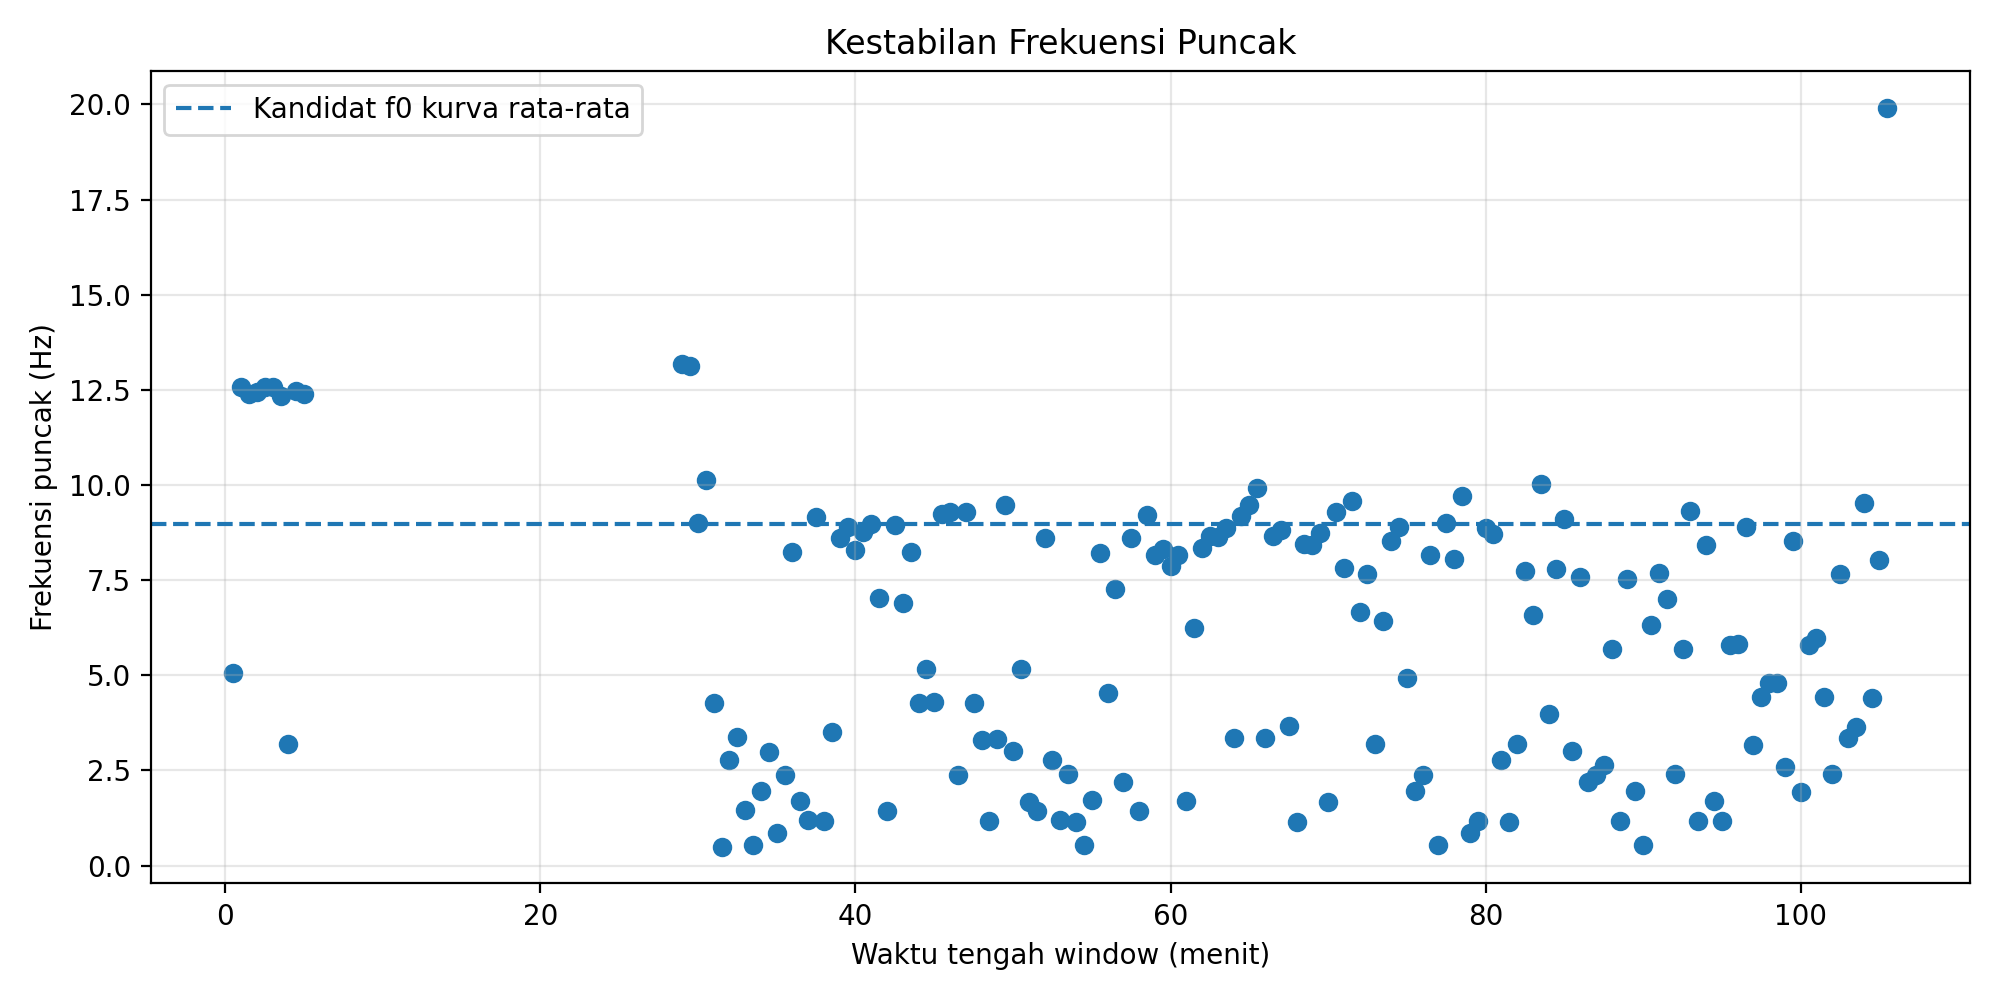 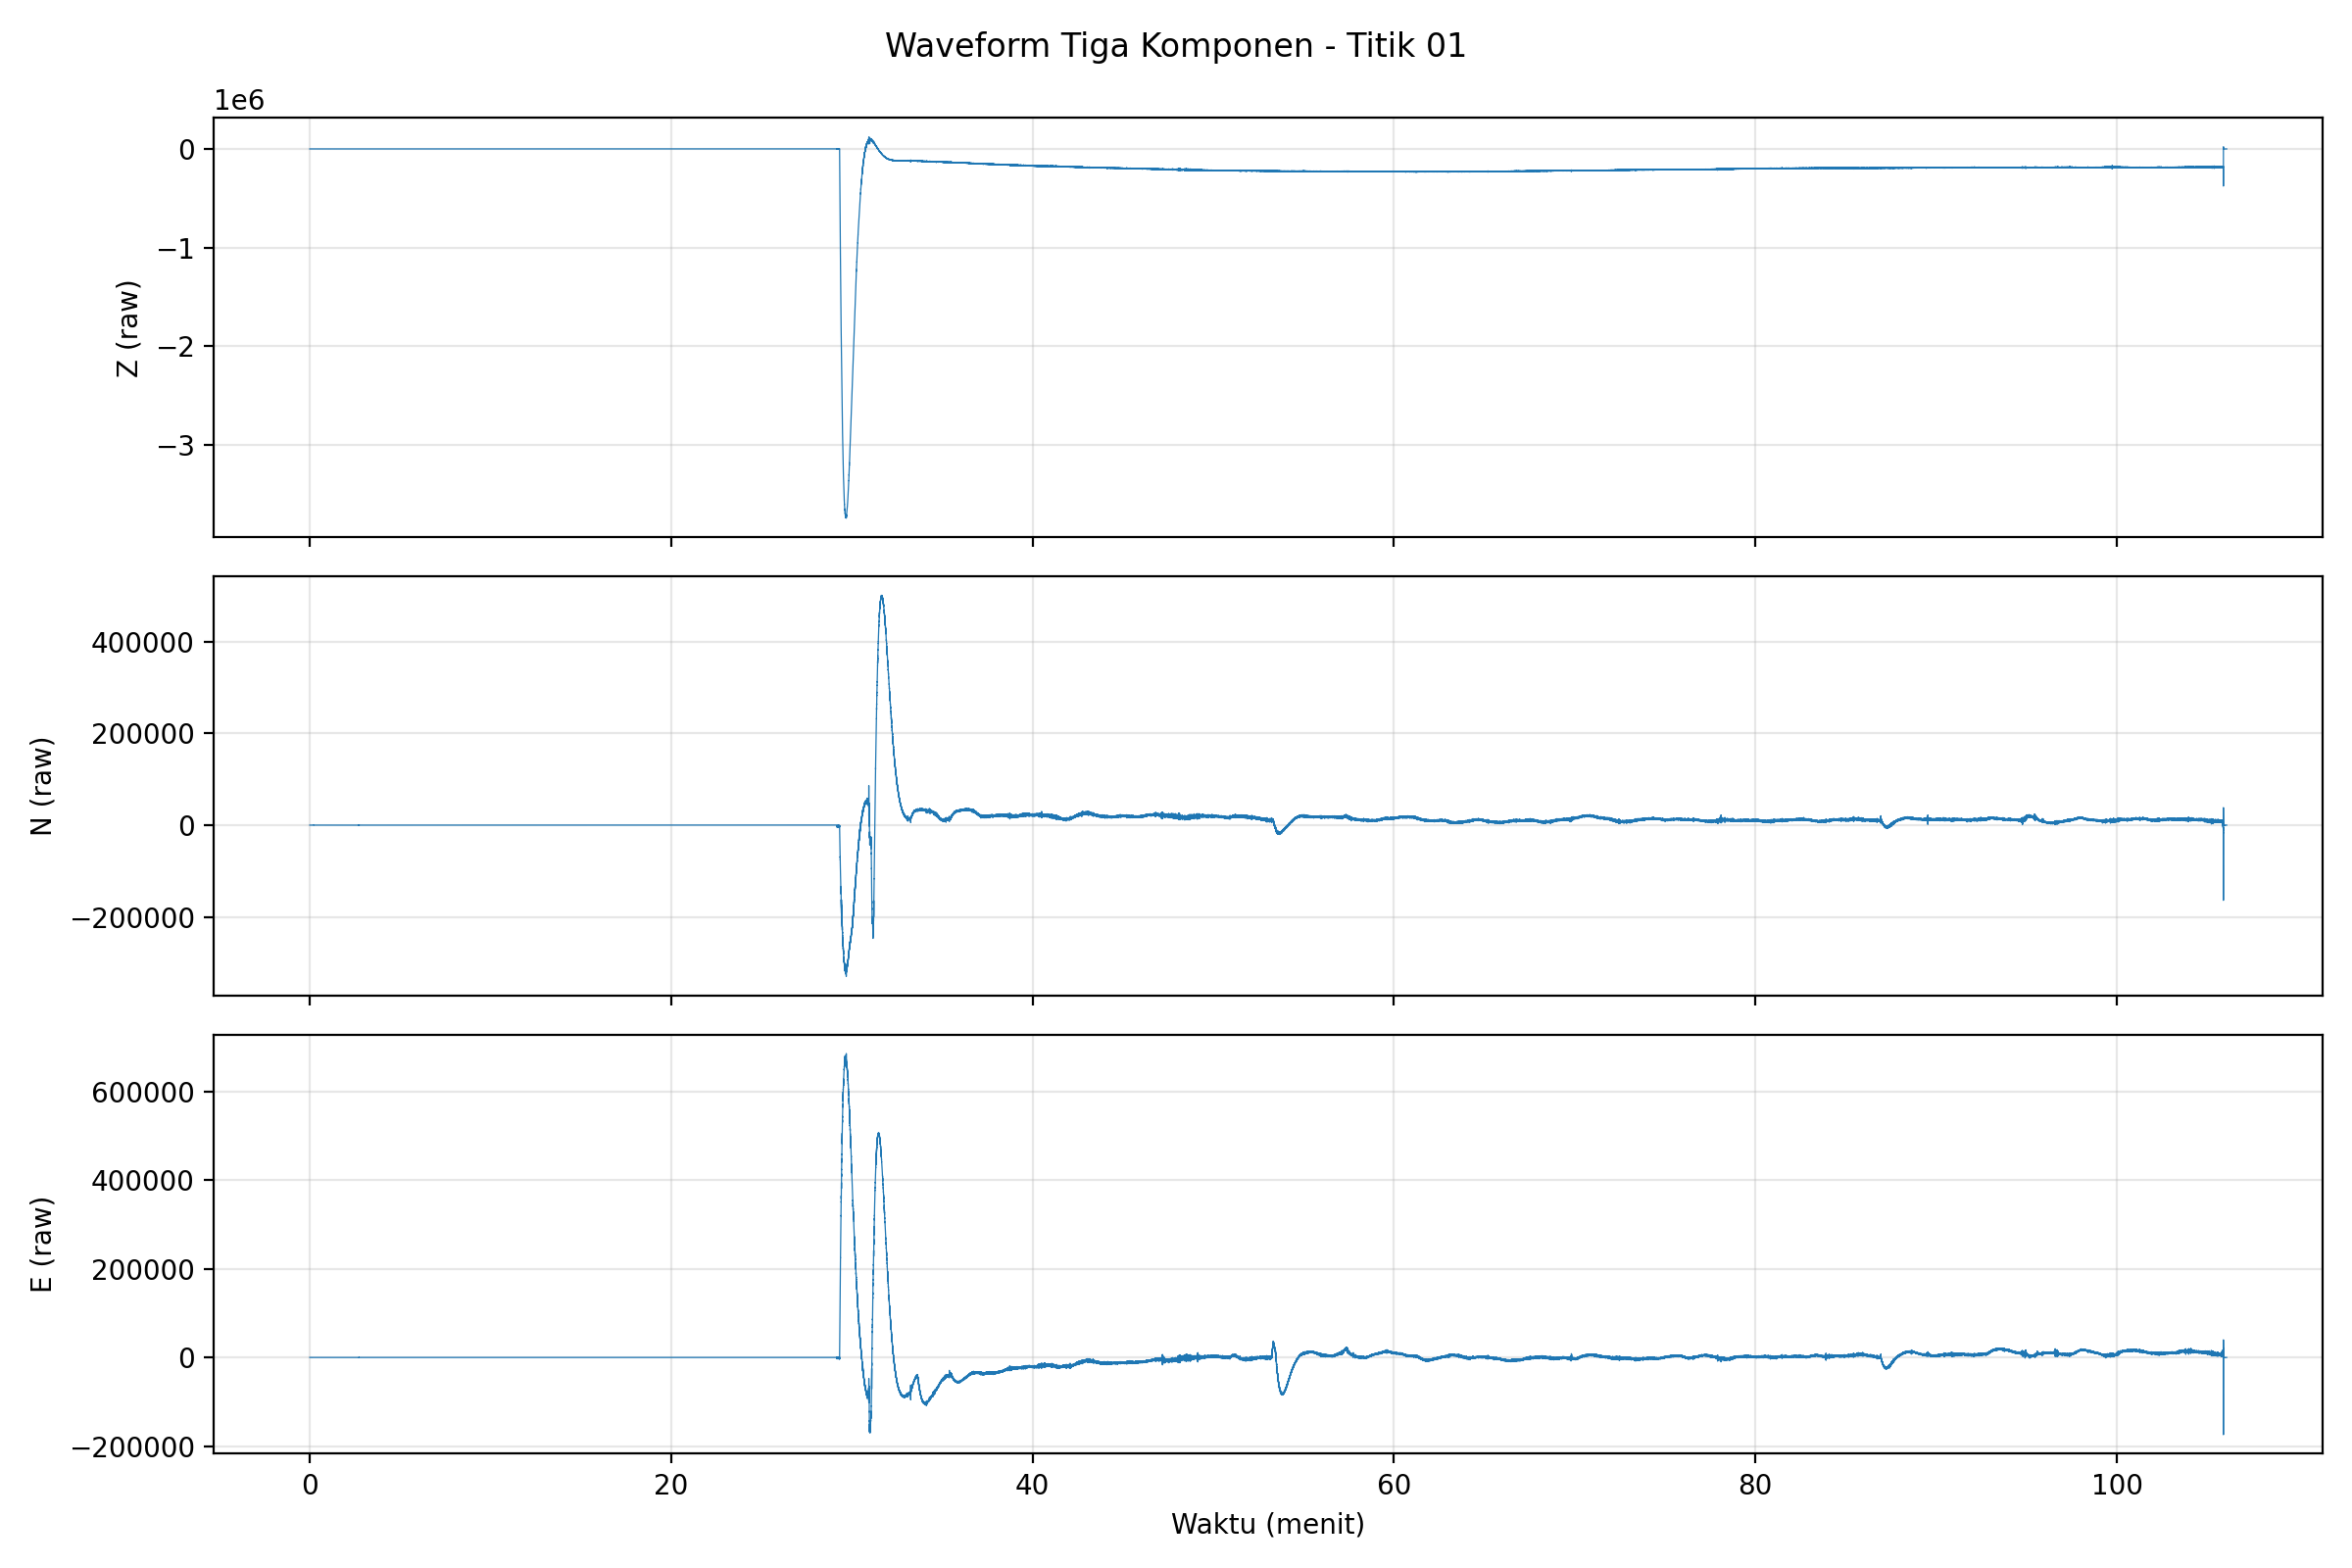 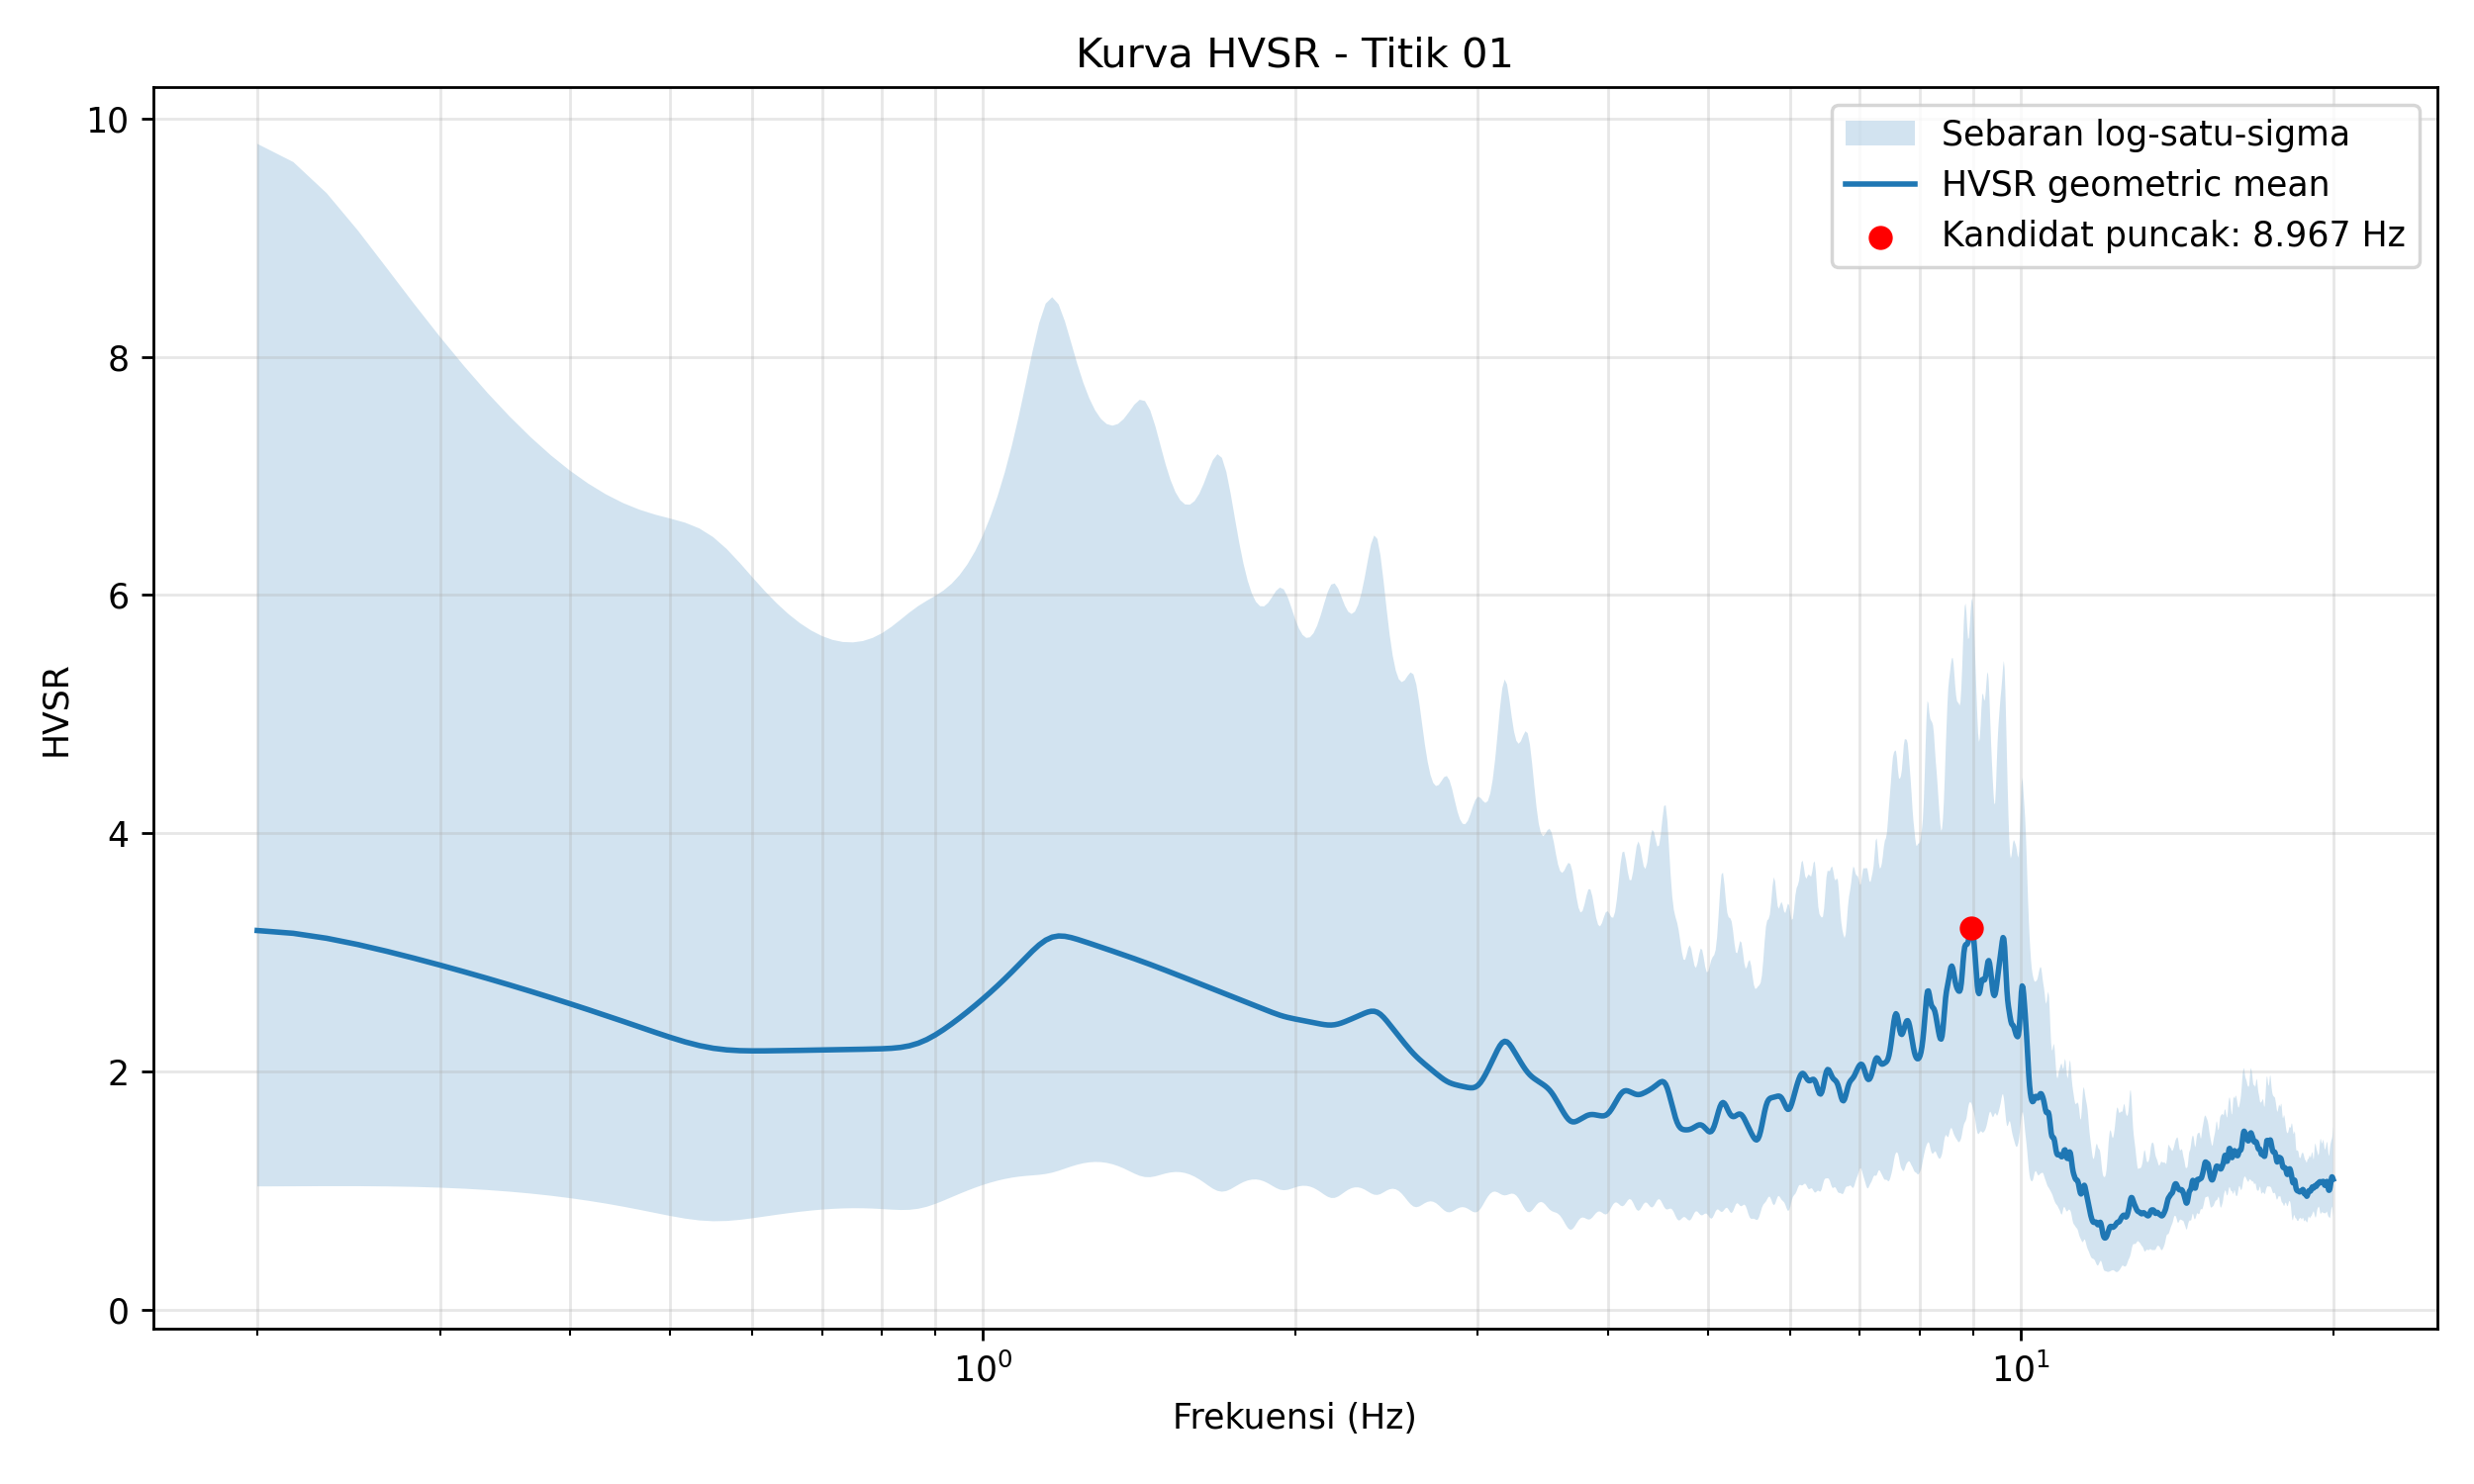

**Hasil analisis HVSR** 

Puncak lokal pada frekuensi 8,967 Hz dengan amplitudo HVSR sekitar 3,2. Puncak tersebut mengindikasikan kemungkinan adanya resonansi tapak yang berkaitan dengan kontras impedansi bawah permukaan. Analisis kestabilan frekuensi memperlihatkan bahwa sejumlah jendela menghasilkan kandidat puncak pada kisaran 8–10 Hz, meskipun distribusi frekuensi puncak secara keseluruhan masih cukup bervariasi. Selain itu, waveform tiga komponen memperlihatkan lonjakan amplitudo yang tajam sekitar menit ke-30, sehingga kualitas sinyal dan pemilihan jendela perlu diperiksa lebih lanjut. Oleh karena itu, frekuensi 8,967 Hz untuk sementara diperlakukan sebagai kandidat frekuensi fundamental dan perlu divalidasi menggunakan kriteria reliabilitas HVSR sebelum digunakan dalam interpretasi struktur bawah permukaan.

### ***PROMPT 3: ANALISIS DATA WELL LOG***

#### ***Judul: Analisis Data Well Log untuk Identifikasi Litologi dan Karakteristik Bawah Permukaan***

Bertindaklah sebagai ahli geofisika eksplorasi dan dosen pembimbing praktikum Geofisika yang menguasai pengolahan dan interpretasi well log. Lakukan analisis data well log untuk mengidentifikasi perubahan karakteristik batuan, membagi interval kedalaman, dan memperkirakan kemungkinan litologi berdasarkan respons log.

Gunakan data kedalaman, GR, resistivitas, densitas, neutron, sonic, atau log lain yang tersedia. Lakukan pemeriksaan data, preprocessing, pembuatan grafik log, identifikasi perubahan respons, pembagian interval, dan interpretasi litologi. Jangan menentukan litologi secara pasti jika data tidak mencukupi dan jangan mengarang data. Sajikan grafik log, tabel interval, kemungkinan litologi, karakteristik batuan, kode Python jika diperlukan, interpretasi, dan kesimpulan. Periksa kembali kualitas data, satuan, kedalaman, nilai ekstrem, batas interval, dan kesesuaian interpretasi antarlog.

<hr>

HASIL PEMBACAAN FILE LAS
File: D:\Study6.las
Jumlah sampel valid: 422
Jumlah kolom data: 14
Kedalaman minimum: 16250.0 ft
Kedalaman maksimum: 16460.5 ft
Nama kurva: ['DEPTH', 'CALI', 'DPHI', 'DRHO', 'GR', 'ILD', 'ILM', 'NPHI', 'SFL', 'SP', 'RXO_RT', 'PHIA', 'BVW', 'SW']
Jumlah baris dilewati: 1

Contoh baris yang dilewati:


,baris,jumlah_nilai,alasan
0,476,11,Diharapkan 14 nilai



Ringkasan QC:


,Kurva,Data_valid,Data_null,Minimum,Median,Maksimum
0,CALI,422,0,7.8560,8.79900,11.1020
1,DPHI,422,0,-0.0684,0.01870,0.4094
2,DRHO,422,0,-0.0060,0.04650,0.3450
3,GR,422,0,14.3520,30.98450,142.7600
4,ILD,422,0,13.4170,177.26000,1945.0610
5,ILM,422,0,11.1430,171.61250,1527.8990
6,NPHI,422,0,-0.0010,0.06200,0.2590
7,SFL,422,0,15.5650,178.92100,1707.9750
8,SP,422,0,-108.0010,-39.63850,10.0640
9,RXO_RT,422,0,0.4560,1.38020,3.7375



Kurva yang terdeteksi:
- CALI
- DPHI
- DRHO
- GR
- ILD
- ILM
- NPHI
- SFL
- SP
- RXO_RT
- PHIA
- BVW
- SW


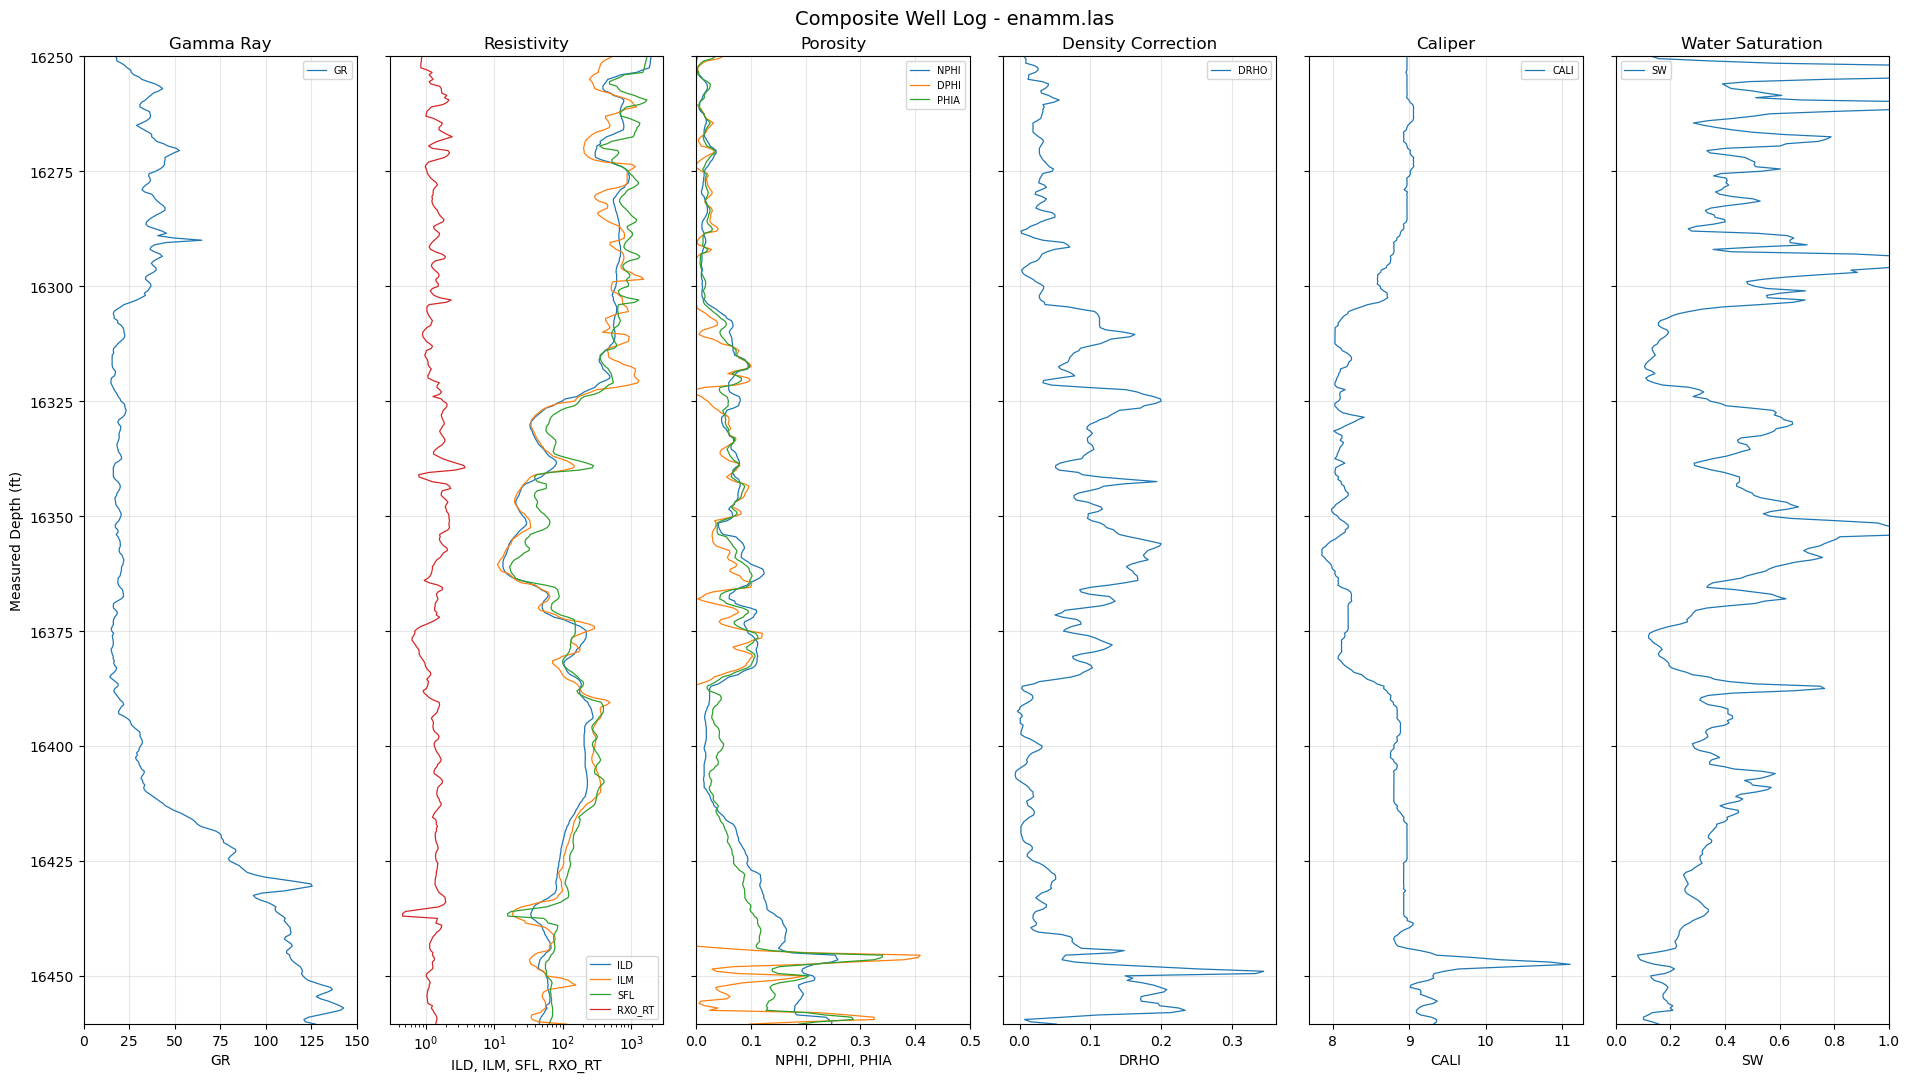


Interval berdasarkan kelas GR:


,Top_ft,Base_ft,Thickness_ft,GR_mean_API,GR_min_API,GR_max_API,ILD_median,NPHI_median,DPHI_median,PHIA_median,GR_class,N_samples
0,16250.0,16254.5,4.5,22.308,17.553,27.462,1874.149,0.001,0.006,0.004,Relatif bersih,9
1,16254.5,16265.0,10.5,35.541,30.456,43.417,687.575,0.013,-0.006,0.015,Transisi,21
2,16265.5,16290.0,24.5,40.167,31.021,52.639,638.355,0.015,0.020,0.018,Transisi,49
3,16290.5,16303.0,12.5,37.461,31.647,45.196,615.082,0.010,-0.008,0.012,Transisi,25
4,16303.0,16397.0,94.0,18.897,14.352,29.362,89.565,0.068,0.058,0.065,Relatif bersih,188
5,16397.0,16401.5,4.5,31.230,30.259,32.266,205.649,0.017,-0.061,0.045,Transisi,9
6,16401.5,16403.5,2.0,29.016,28.465,29.523,213.438,0.017,-0.051,0.038,Relatif bersih,4
7,16403.5,16416.5,13.0,39.208,30.222,59.798,213.478,0.019,-0.034,0.031,Transisi,26
8,16416.5,16461.0,44.5,107.023,61.288,142.760,62.661,0.154,-0.020,0.112,Kaya lempung,89


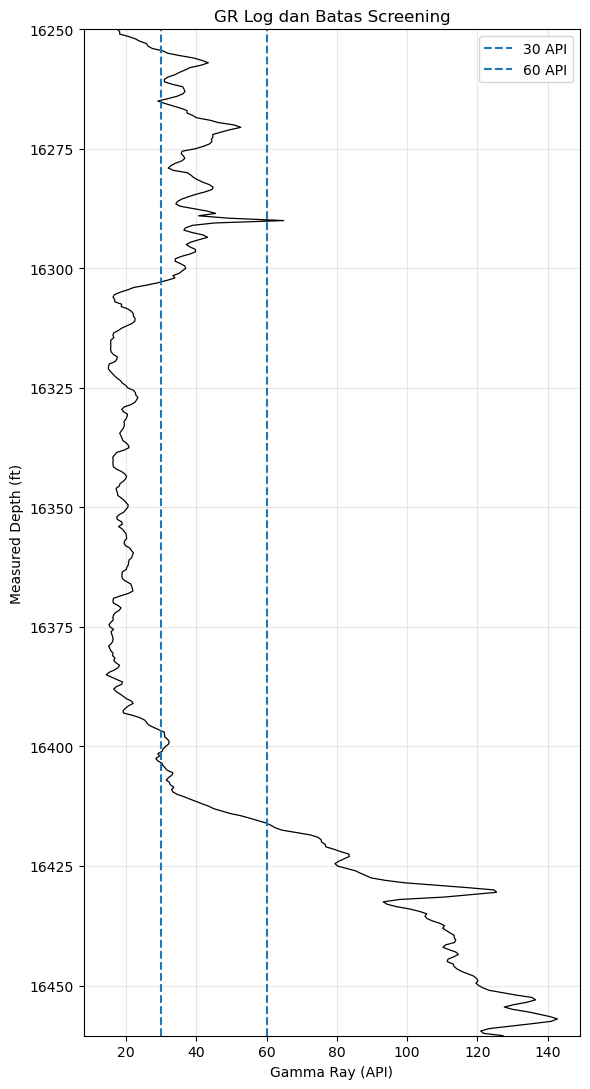


ANALISIS SELESAI
Folder hasil: D:\KULIAH\SEMESTER 6\AI\hasil_analisis_well_log
File hasil:
- 01_quality_control.csv
- 02_composite_well_log.png
- 03_interval_kedalaman.csv
- 04_data_bersih_dan_kelas.csv
- 05_data_perlu_diperiksa.csv
- 06_gr_screening.png
- 07_laporan_ringkas.txt

Interpretasi GR ini adalah screening awal. Batas GR 30 dan 60 API merupakan parameter yang dapat diubah sesuai karakter formasi dan konteks geologi.


In [14]:

# ==============================================================
# ANALISIS WELL LOG ENAMM.LAS
# Versi: pembacaan manual tanpa lasio.read()
# ==============================================================

from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------------------------
# 1. PENGATURAN
# --------------------------------------------------------------

FILE_LAS = Path(r"D:\Study6.las")
OUTPUT_DIR = Path("hasil_analisis_well_log")
OUTPUT_DIR.mkdir(exist_ok=True, parents=True)

GR_CLEAN = 30.0
GR_SHALE = 60.0
MIN_INTERVAL_FT = 2.0

# Kode null standar LAS; nilai null dari header juga dibaca
NULL_VALUE = -999.25

if not FILE_LAS.exists():
    raise FileNotFoundError(
        f"File {FILE_LAS.resolve()} tidak ditemukan.\n"
        "Unggah enamm.las ke folder kerja Jupyter atau "
        "ubah FILE_LAS menjadi path lengkap."
    )

# --------------------------------------------------------------
# 2. BACA HEADER DAN DATA LAS SECARA MANUAL
# --------------------------------------------------------------

lines = FILE_LAS.read_text(
    encoding="utf-8", errors="replace"
).splitlines()

# Cari bagian data ~A
data_start = None

for i, line in enumerate(lines):
    if re.match(r"^\s*~A(?:\s|$)", line, flags=re.IGNORECASE):
        data_start = i
        break

if data_start is None:
    raise ValueError("Bagian data ~A tidak ditemukan dalam file LAS.")

# Ambil nama kurva dari bagian ~C
curve_names = []
inside_curve_section = False

for line in lines[:data_start]:
    stripped = line.strip()

    if stripped.startswith("#") or not stripped:
        continue

    if stripped.startswith("~"):
        inside_curve_section = stripped.upper().startswith("~C")
        continue

    if inside_curve_section:
        # Format header kurva biasanya: DEPT.FT : DESCRIPTION
        match = re.match(r"^\s*([^\s.]+)\s*\.\s*([^\s:]*)", line)

        if match:
            name = match.group(1).strip()
            if name.upper() not in [n.upper() for n in curve_names]:
                curve_names.append(name)

# Ambil informasi null dari header bila tersedia
for line in lines[:data_start]:
    if re.match(r"^\s*NULL\s*\.", line, flags=re.IGNORECASE):
        match = re.search(
            r"NULL\s*\.\s*\S+\s+([-+]?\d*\.?\d+(?:[Ee][-+]?\d+)?)",
            line,
            flags=re.IGNORECASE
        )
        if match:
            NULL_VALUE = float(match.group(1))
        break

# Baris pertama ~A dapat berisi nama kolom.
# Jika tidak, gunakan nama kurva dari header.
first_data_tokens = lines[data_start].split()
data_header_tokens = first_data_tokens[1:]

records = []
bad_rows = []
expected_columns = None

# Gunakan jumlah nama kurva dari header bila berhasil ditemukan
if curve_names:
    expected_columns = len(curve_names)

# Baca data numerik
for line_no, line in enumerate(lines[data_start + 1:], start=data_start + 2):
    stripped = line.strip()

    if not stripped or stripped.startswith("#"):
        continue

    # Hanya proses baris yang terlihat seperti baris numerik
    tokens = stripped.split()

    try:
        values = [float(token.replace("D", "E").replace("d", "e"))
                  for token in tokens]
    except ValueError:
        bad_rows.append({
            "baris": line_no,
            "jumlah_nilai": len(tokens),
            "alasan": "Baris bukan numerik atau format angka tidak dikenal"
        })
        continue

    if expected_columns is None:
        # Tentukan jumlah kolom dari baris numerik lengkap pertama
        expected_columns = len(values)

    if len(values) != expected_columns:
        bad_rows.append({
            "baris": line_no,
            "jumlah_nilai": len(values),
            "alasan": f"Diharapkan {expected_columns} nilai"
        })
        continue

    records.append(values)

if not records:
    raise ValueError(
        "Tidak ada baris data yang berhasil dibaca. "
        "Periksa format bagian ~A dan header ~C."
    )

# Nama kolom harus sama jumlahnya dengan data
if curve_names and len(curve_names) == expected_columns:
    columns = curve_names
else:
    columns = [f"CURVE_{i+1}" for i in range(expected_columns)]
    warnings.warn(
        "Nama kurva dari header tidak cocok dengan jumlah kolom. "
        "Kolom sementara digunakan; periksa header LAS."
    )

df = pd.DataFrame(records, columns=columns)

# Normalisasi nama kurva
df.columns = [str(c).strip().upper() for c in df.columns]

# Jika nama kedalaman tidak terdeteksi, kolom pertama dianggap kedalaman
depth_candidates = ["DEPT", "DEPTH", "MD", "CURVE_1"]
depth_col = next(
    (c for c in depth_candidates if c in df.columns),
    df.columns[0]
)

if depth_col != "DEPTH":
    df.rename(columns={depth_col: "DEPTH"}, inplace=True)

# Ubah kode null menjadi NaN
df.replace(NULL_VALUE, np.nan, inplace=True)
df.replace(-999.25, np.nan, inplace=True)

# Buang sampel yang tidak memiliki kedalaman valid
df["DEPTH"] = pd.to_numeric(df["DEPTH"], errors="coerce")
df.dropna(subset=["DEPTH"], inplace=True)
df.sort_values("DEPTH", inplace=True)
df.reset_index(drop=True, inplace=True)

# Pastikan seluruh kolom log numerik
for col in df.columns:
    if col != "DEPTH":
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Alias nama kurva resistivitas yang umum
if "RX0_RT" in df.columns and "RXO_RT" not in df.columns:
    df.rename(columns={"RX0_RT": "RXO_RT"}, inplace=True)

print("=" * 70)
print("HASIL PEMBACAAN FILE LAS")
print("=" * 70)
print("File:", FILE_LAS.resolve())
print("Jumlah sampel valid:", len(df))
print("Jumlah kolom data:", len(df.columns))
print("Kedalaman minimum:", df["DEPTH"].min(), "ft")
print("Kedalaman maksimum:", df["DEPTH"].max(), "ft")
print("Nama kurva:", df.columns.tolist())
print("Jumlah baris dilewati:", len(bad_rows))

if bad_rows:
    print("\nContoh baris yang dilewati:")
    display(pd.DataFrame(bad_rows).head(20))

# --------------------------------------------------------------
# 3. QUALITY CONTROL (QC)
# --------------------------------------------------------------

log_columns = [c for c in df.columns if c != "DEPTH"]

qc = pd.DataFrame({
    "Kurva": log_columns,
    "Data_valid": [df[c].notna().sum() for c in log_columns],
    "Data_null": [df[c].isna().sum() for c in log_columns],
    "Minimum": [
        df[c].min() if df[c].notna().any() else np.nan
        for c in log_columns
    ],
    "Median": [
        df[c].median() if df[c].notna().any() else np.nan
        for c in log_columns
    ],
    "Maksimum": [
        df[c].max() if df[c].notna().any() else np.nan
        for c in log_columns
    ],
})

qc.to_csv(OUTPUT_DIR / "01_quality_control.csv", index=False)

print("\nRingkasan QC:")
display(qc)

# --------------------------------------------------------------
# 4. IDENTIFIKASI KURVA
# --------------------------------------------------------------

print("\nKurva yang terdeteksi:")

for c in log_columns:
    print("-", c)

if "GR" not in df.columns:
    raise ValueError(
        "Kurva GR tidak ditemukan. "
        "Periksa nama kurva pada header LAS."
    )

# --------------------------------------------------------------
# 5. COMPOSITE WELL LOG
# --------------------------------------------------------------

track_definitions = [
    ("Gamma Ray", ["GR"], (0, 150)),
    ("Resistivity", ["ILD", "ILM", "SFL", "RXO_RT"], None),
    ("Porosity", ["NPHI", "DPHI", "PHIA", "NPHIC"], (0, 0.5)),
    ("Density Correction", ["DRHO"], None),
    ("Caliper", ["CALI"], None),
    ("Water Saturation", ["SW"], (0, 1)),
]

available_tracks = []

for title, candidates, xlim in track_definitions:
    present = [c for c in candidates if c in df.columns]
    if present:
        available_tracks.append((title, present, xlim))

fig, axes = plt.subplots(
    1,
    len(available_tracks),
    figsize=(3.2 * len(available_tracks), 11),
    sharey=True,
    squeeze=False
)

axes = axes.ravel()

for ax, (title, curves, xlim) in zip(axes, available_tracks):
    for curve in curves:
        values = df[curve]

        if title == "Resistivity":
            values = values.where(values > 0)
            ax.plot(values, df["DEPTH"], label=curve, linewidth=0.9)
            ax.set_xscale("log")
        else:
            ax.plot(values, df["DEPTH"], label=curve, linewidth=0.9)

    ax.set_title(title)
    ax.set_xlabel(", ".join(curves))
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=7, loc="best")

    if xlim is not None:
        ax.set_xlim(xlim)

    ax.set_ylim(df["DEPTH"].max(), df["DEPTH"].min())

axes[0].set_ylabel("Measured Depth (ft)")
fig.suptitle("Composite Well Log - enamm.las", fontsize=14)
fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "02_composite_well_log.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# --------------------------------------------------------------
# 6. KLASIFIKASI AWAL BERDASARKAN GR
# --------------------------------------------------------------

def classify_gr(value):
    if pd.isna(value):
        return "GR tidak tersedia"
    if value < GR_CLEAN:
        return "Relatif bersih"
    if value < GR_SHALE:
        return "Transisi"
    return "Kaya lempung"

df["GR_CLASS"] = df["GR"].apply(classify_gr)

# Flag saturasi air di luar rentang fisik jika SW adalah fraksi
if "SW" in df.columns:
    df["SW_FLAG"] = np.where(
        df["SW"].notna() & ((df["SW"] < 0) | (df["SW"] > 1)),
        "Periksa SW",
        ""
    )

# --------------------------------------------------------------
# 7. DETEKSI INTERVAL BERDASARKAN KELAS GR
# --------------------------------------------------------------

# Estimasi step kedalaman dari median selisih kedalaman
depth_steps = df["DEPTH"].diff().dropna()
depth_steps = depth_steps[depth_steps > 0]

if depth_steps.empty:
    raise ValueError("Tidak dapat menghitung interval sampling kedalaman.")

depth_step = float(depth_steps.median())

df["SEGMENT"] = (
    df["GR_CLASS"] != df["GR_CLASS"].shift()
).cumsum()

intervals = []

for _, group in df.groupby("SEGMENT", sort=True):
    top = float(group["DEPTH"].min())
    last_sample = float(group["DEPTH"].max())
    base = last_sample + depth_step
    thickness = base - top

    if thickness < MIN_INTERVAL_FT:
        continue

    intervals.append({
        "Top_ft": top,
        "Base_ft": base,
        "Thickness_ft": thickness,
        "GR_mean_API": group["GR"].mean(),
        "GR_min_API": group["GR"].min(),
        "GR_max_API": group["GR"].max(),
        "ILD_median": group["ILD"].median()
            if "ILD" in group.columns else np.nan,
        "NPHI_median": group["NPHI"].median()
            if "NPHI" in group.columns else np.nan,
        "DPHI_median": group["DPHI"].median()
            if "DPHI" in group.columns else np.nan,
        "PHIA_median": group["PHIA"].median()
            if "PHIA" in group.columns else np.nan,
        "GR_class": group["GR_CLASS"].iloc[0],
        "N_samples": len(group)
    })

interval_df = pd.DataFrame(intervals)

interval_df.to_csv(
    OUTPUT_DIR / "03_interval_kedalaman.csv",
    index=False
)

df.to_csv(
    OUTPUT_DIR / "04_data_bersih_dan_kelas.csv",
    index=False
)

print("\nInterval berdasarkan kelas GR:")
display(interval_df.round(3))

# --------------------------------------------------------------
# 8. FLAG NILAI YANG PERLU DIVERIFIKASI
# --------------------------------------------------------------

flags = []

# SW: jika dimaksudkan sebagai fraksi, harus antara 0 dan 1
if "SW" in df.columns:
    invalid = df["SW"].notna() & ((df["SW"] < 0) | (df["SW"] > 1))

    for _, row in df.loc[invalid, ["DEPTH", "SW"]].iterrows():
        flags.append({
            "Depth_ft": row["DEPTH"],
            "Curve": "SW",
            "Value": row["SW"],
            "Issue": "Di luar rentang 0-1; periksa definisi/unit/rumus"
        })

# Flag nilai porositas hanya jika kurva dinyatakan dalam v/v
for curve in ["NPHI", "DPHI", "PHIA", "NPHIC"]:
    if curve not in df.columns:
        continue

    invalid = df[curve].notna() & ((df[curve] < 0) | (df[curve] > 1))

    for _, row in df.loc[invalid, ["DEPTH", curve]].iterrows():
        flags.append({
            "Depth_ft": row["DEPTH"],
            "Curve": curve,
            "Value": row[curve],
            "Issue": "Di luar rentang 0-1 jika unit berupa fraksi; periksa unit"
        })

flag_df = pd.DataFrame(
    flags,
    columns=["Depth_ft", "Curve", "Value", "Issue"]
)

flag_df.to_csv(
    OUTPUT_DIR / "05_data_perlu_diperiksa.csv",
    index=False
)

# --------------------------------------------------------------
# 9. PLOT GR DAN BATAS KLASIFIKASI
# --------------------------------------------------------------

fig, ax = plt.subplots(figsize=(6, 11))

ax.plot(df["GR"], df["DEPTH"], color="black", linewidth=0.9)
ax.axvline(GR_CLEAN, linestyle="--", label=f"{GR_CLEAN:g} API")
ax.axvline(GR_SHALE, linestyle="--", label=f"{GR_SHALE:g} API")

ax.set_xlabel("Gamma Ray (API)")
ax.set_ylabel("Measured Depth (ft)")
ax.set_title("GR Log dan Batas Screening")
ax.set_ylim(df["DEPTH"].max(), df["DEPTH"].min())
ax.grid(True, alpha=0.3)
ax.legend()

fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "06_gr_screening.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# --------------------------------------------------------------
# 10. SIMPAN LAPORAN TEKS
# --------------------------------------------------------------

report = [
    "LAPORAN RINGKAS ANALISIS WELL LOG",
    f"File: {FILE_LAS.name}",
    f"Jumlah sampel valid: {len(df)}",
    f"Kedalaman awal: {df['DEPTH'].min():.3f} ft",
    f"Kedalaman akhir: {df['DEPTH'].max():.3f} ft",
    f"Median step kedalaman: {depth_step:.3f} ft",
    f"Jumlah baris dilewati: {len(bad_rows)}",
    f"Jumlah interval GR: {len(interval_df)}",
    f"Jumlah flag pemeriksaan: {len(flag_df)}",
    "",
    "CATATAN INTERPRETASI:",
    "- GR rendah berarti relatif bersih, bukan otomatis sandstone.",
    "- GR tinggi menunjukkan respons kaya radioaktivitas/lempung,",
    "  tetapi bukan bukti litologi tunggal.",
    "- Evaluasi reservoir memerlukan kombinasi log dan konteks geologi.",
    "- Jangan menyimpulkan hidrokarbon hanya dari resistivitas tinggi.",
    "- Verifikasi unit porositas dan rumus SW sebelum interpretasi."
]

(OUTPUT_DIR / "07_laporan_ringkas.txt").write_text(
    "\n".join(report),
    encoding="utf-8"
)

print("\n" + "=" * 70)
print("ANALISIS SELESAI")
print("=" * 70)
print("Folder hasil:", OUTPUT_DIR.resolve())
print("File hasil:")
for p in sorted(OUTPUT_DIR.iterdir()):
    print("-", p.name)

print(
    "\nInterpretasi GR ini adalah screening awal. "
    "Batas GR 30 dan 60 API merupakan parameter yang dapat diubah "
    "sesuai karakter formasi dan konteks geologi."
)


**Composite Well Log**

**- Gamma Ray (GR):** Nilai GR relatif rendah pada interval sekitar 16.300–16.390 ft, mengindikasikan kemungkinan batuan bersih dengan kandungan serpih rendah. Di bawah sekitar 16.400 ft, GR meningkat tajam hingga lebih dari 100 API, yang mengindikasikan peningkatan kandungan serpih atau mineral radioaktif.

**- Resistivitas:** Terdapat perubahan resistivitas antarlapisan. Resistivitas yang relatif tinggi dapat menunjukkan formasi yang lebih resistif, tetapi interpretasinya perlu dikombinasikan dengan porositas dan saturasi air.

**- Porositas:** Kurva NPHI, DPHI, dan PHIA menunjukkan variasi porositas. Perbedaan antarkurva dapat berkaitan dengan perubahan litologi atau efek fluida, tetapi perlu dikaji bersama data pendukung.

**- Density Correction (DRHO):** Nilainya berfluktuasi dan terdapat anomali yang cukup besar di beberapa interval. Bagian tersebut perlu diperiksa karena kemungkinan menunjukkan kualitas pembacaan densitas yang kurang baik.

**- Caliper:** Diameter lubang bor umumnya berada di sekitar 8–9 inci, tetapi membesar hingga sekitar 11 inci pada interval tertentu. Pembesaran lubang dapat memengaruhi kualitas log densitas dan neutron.

**- Water Saturation (SW):** Nilai SW bervariasi dari rendah hingga tinggi. Nilai rendah dapat mengindikasikan potensi hidrokarbon, tetapi tidak cukup untuk memastikan keberadaan hidrokarbon tanpa validasi parameter petrofisika lainnya.

**2. Gamma Ray Log dan Batas Screening**
Gambar kedua memperlihatkan batas screening GR sebesar 30 API dan 60 API. Pada interval sekitar 16.250–16.305 ft, GR umumnya berada di bawah 30 API, sehingga berpotensi menunjukkan batuan bersih. Pada interval sekitar 16.305–16.400 ft, GR sebagian besar tetap rendah. Mulai sekitar 16.400 ft, GR meningkat dan melewati 60 API pada beberapa bagian hingga akhir interval, yang mengindikasikan kemungkinan formasi lebih serpih.

**Kesimpulan:** 

Sumur menunjukkan perubahan karakteristik formasi yang cukup jelas, terutama pada interval sekitar 16.400 ft, ditandai peningkatan GR dan perubahan respons log lainnya. Interval dengan GR rendah layak diperiksa lebih lanjut sebagai kandidat batuan reservoir, sedangkan interval dengan GR tinggi berpotensi memiliki kandungan serpih lebih besar. Namun, penentuan litologi, kualitas reservoir, dan potensi hidrokarbon perlu dikonfirmasi menggunakan nilai log numerik, koreksi kualitas data, serta evaluasi porositas dan saturasi air secara terpadu.

### ***PROMPT 4: PEMROSESAN DATA SPAC***

### ***Judul: Analisis Data Mikrotremor Menggunakan Metode Spatial Autocorrelation (SPAC)***

Bertindaklah sebagai ahli seismologi dan geofisika near-surface serta dosen pembimbing praktikum Geofisika yang menguasai metode SPAC, mikrotremor array, gelombang permukaan, kurva dispersi, dan inversi Vs. Lakukan pengolahan data SPAC untuk memperoleh kurva dispersi dan profil Vs terhadap kedalaman.

Gunakan waveform, konfigurasi array, posisi sensor, jarak atau radius array, durasi perekaman, dan frekuensi sampling yang diberikan. Lakukan pemeriksaan data, preprocessing, analisis korelasi spasial, perhitungan SPAC, pembuatan kurva dispersi, inversi, dan interpretasi profil Vs. Gunakan bahasa ilmiah yang mudah dipahami mahasiswa S1 Geofisika, jangan mengarang nilai dan jelaskan ketidakpastian hasil. Sajikan hasil pengolahan, kurva dispersi, model Vs, tabel lapisan, interpretasi bawah permukaan, dan kesimpulan. Periksa kembali waveform, konfigurasi array, kurva SPAC, kesesuaian kurva observasi dan model, serta hasil inversi sebelum memberikan jawaban akhir.

<hr>


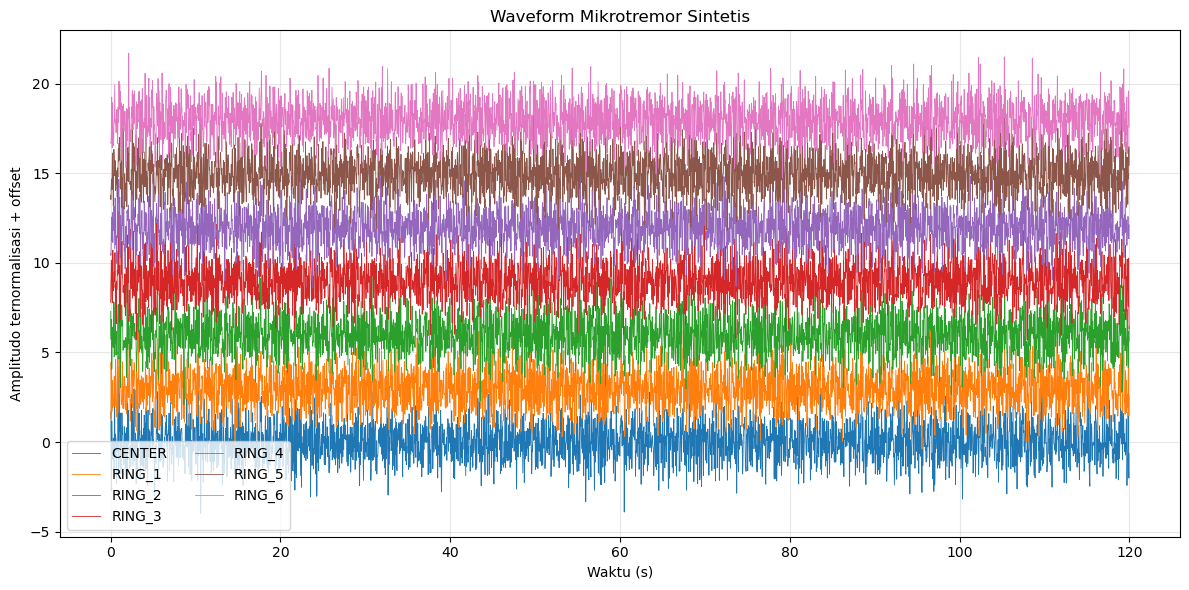


=== MODEL BAWAH PERMUKAAN SINTETIS ===


,Lapisan,Top_m,Base_m,Thickness_m,Vs_model_awal_m_s,Vs_inversi_m_s
0,1,0.0,5.0,5.0,180.0,123.59
1,2,5.0,20.0,15.0,320.0,418.97
2,3,20.0,NaN,NaN,600.0,555.28


Konvergensi optimizer: True
RMS relatif dispersi: 29.06%


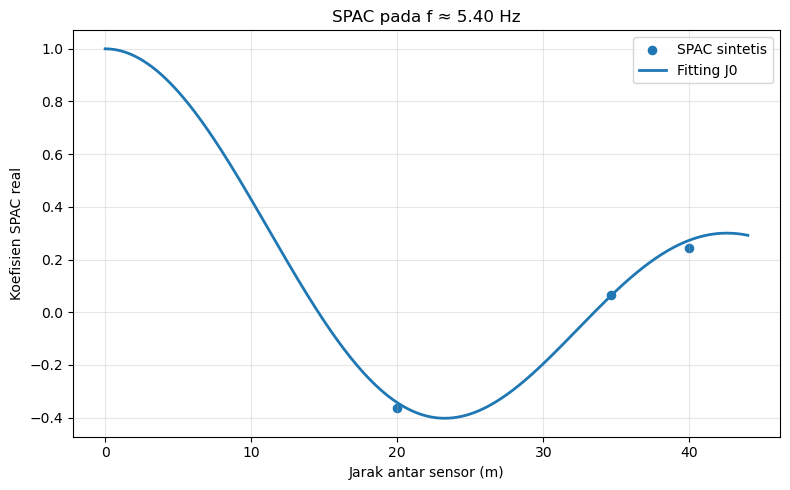

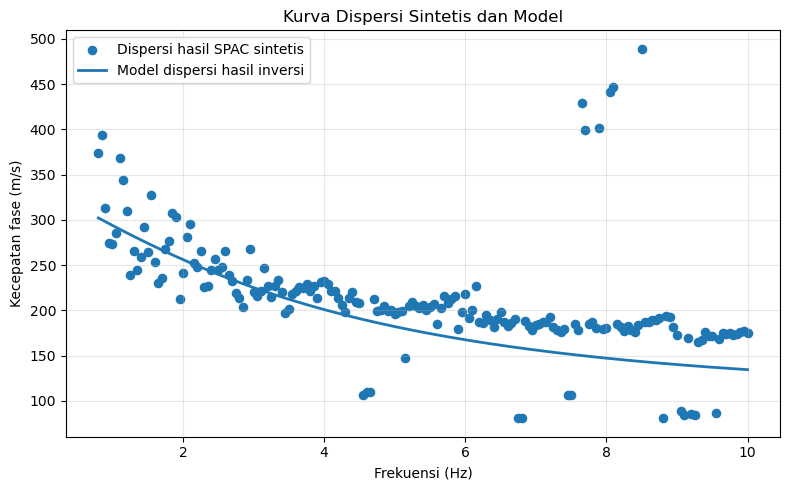

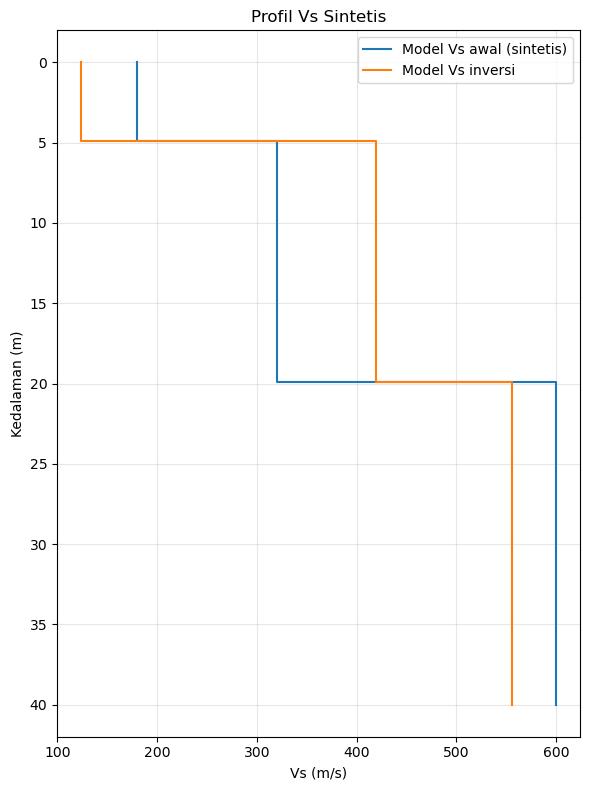


=== RINGKASAN ===


,Parameter,Nilai
0,Jumlah sensor sintetis,7
1,Sampling rate (Hz),40.0
2,Durasi (s),120.0
3,Radius array (m),20.0
4,Jumlah titik dispersi,185
5,RMS relatif dispersi (%),29.05996
6,Optimizer konvergen,True



Semua hasil simulasi tersimpan di:
D:\KULIAH\SEMESTER 6\AI\hasil_simulasi_SPAC

PERINGATAN ILMIAH: hasil ini adalah SIMULASI. Model forward dispersi menggunakan pendekatan pedagogis, bukan solver elastik Rayleigh. Jangan gunakan nilai Vs ini sebagai hasil survei lapangan atau laporan penelitian.


In [18]:

# ============================================================
# SIMULASI SPAC: WAVEFORM -> SPAC -> DISPERSI -> INVERSI Vs
# Semua data yang dihasilkan adalah SIMULASI.
#
# Catatan ilmiah:
# Forward model dispersi di sini adalah pendekatan pedagogis,
# bukan solver mode Rayleigh elastik yang lengkap.
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.special import j0
from scipy.signal import welch, csd
from scipy.optimize import least_squares

# ============================================================
# 1. PARAMETER SIMULASI
# ============================================================

SEED = 42
rng = np.random.default_rng(SEED)

OUT = Path("hasil_simulasi_SPAC")
OUT.mkdir(exist_ok=True)

FS = 40.0                 # sampling rate (Hz)
DURATION = 120.0          # durasi sintetis (detik)
N = int(FS * DURATION)
T = np.arange(N) / FS

# Array: satu sensor di tengah dan enam sensor pada lingkaran
R_ARRAY = 20.0            # radius array (m)
N_RING = 6

angles = np.linspace(0, 2 * np.pi, N_RING, endpoint=False)

positions = np.vstack([
    [0.0, 0.0],
    np.column_stack([
        R_ARRAY * np.cos(angles),
        R_ARRAY * np.sin(angles)
    ])
])

station_names = ["CENTER"] + [
    f"RING_{i+1}" for i in range(N_RING)
]

# Model bawah permukaan sintetis yang dianggap sebagai model benar
# Ketebalan lapisan pertama dan kedua diketahui; lapisan terakhir half-space.
TRUE_THICKNESS = np.array([5.0, 15.0])  # meter
TRUE_VS = np.array([180.0, 320.0, 600.0])  # m/s
TRUE_VP_VS = 1.75
TRUE_POISSON = (
    TRUE_VP_VS**2 - 2
) / (
    2 * (TRUE_VP_VS**2 - 1)
)

# ============================================================
# 2. FORWARD MODEL DISPERSI SEDERHANA UNTUK LATIHAN
# ============================================================

def pedagogical_phase_velocity(freq, thickness, vs):
    """
    Pendekatan sensitivitas kedalaman untuk tujuan pendidikan.
    BUKAN solver dispersi Rayleigh yang sesungguhnya.

    Vs lapisan lebih dalam diberi bobot lebih besar pada
    frekuensi rendah; lapisan dangkal lebih dominan pada
    frekuensi tinggi.
    """
    freq = np.asarray(freq, dtype=float)
    depth_mid = np.cumsum(thickness) - thickness / 2
    depth_mid = np.r_[depth_mid, np.sum(thickness) + 10.0]

    # Bobot sensitivitas yang menurun terhadap kedalaman
    weights = np.exp(
        -2 * np.pi * freq[:, None] * depth_mid[None, :]
        / 250.0
    )

    # Half-space diberi kedalaman representatif
    weights /= weights.sum(axis=1, keepdims=True)

    # Faktor pendekatan kecepatan fase Rayleigh
    return 0.92 * (weights @ vs)


# ============================================================
# 3. BUAT WAVEFORM SINTETIS
# ============================================================

freq_fft = np.fft.rfftfreq(N, d=1 / FS)
n_sensor = len(positions)

# Dispersi teoretis model sintetis
valid_f = freq_fft > 0
c_true_fft = np.full_like(freq_fft, np.nan)

c_true_fft[valid_f] = pedagogical_phase_velocity(
    freq_fft[valid_f],
    TRUE_THICKNESS,
    TRUE_VS
)

# Gelombang datang dari banyak arah dengan fase acak.
# Setiap komponen merambat dengan k = 2*pi*f/c(f).
n_directions = 24
directions = rng.uniform(0, 2*np.pi, n_directions)
amplitudes = (
    rng.normal(size=(len(freq_fft), n_directions))
    + 1j * rng.normal(size=(len(freq_fft), n_directions))
)

waveforms = np.zeros((n_sensor, N))

for i, (x, y) in enumerate(positions):
    spectrum = np.zeros(len(freq_fft), dtype=complex)

    for k, f in enumerate(freq_fft):
        if f < 0.5 or f > 12.0 or f == 0:
            continue

        c = c_true_fft[k]
        phase_shift = (
            x * np.cos(directions) + y * np.sin(directions)
        )

        phase = np.exp(
            -1j * 2 * np.pi * f * phase_shift / c
        )

        spectrum[k] = np.sum(amplitudes[k] * phase)

    waveforms[i] = np.fft.irfft(spectrum, n=N)

    # Tambahkan noise kecil
    waveforms[i] += 0.05 * np.std(waveforms[i]) * rng.normal(size=N)

    # Normalisasi amplitudo untuk tampilan
    std = np.std(waveforms[i])
    if std > 0:
        waveforms[i] /= std

# Simpan waveform sintetis
waveform_df = pd.DataFrame(
    waveforms.T,
    columns=station_names
)
waveform_df.insert(0, "time_s", T)
waveform_df.to_csv(OUT / "01_waveform_sintetis.csv", index=False)

# ============================================================
# 4. PLOT WAVEFORM
# ============================================================

fig, ax = plt.subplots(figsize=(12, 6))

for i, name in enumerate(station_names):
    ax.plot(
        T,
        waveforms[i] + i * 3,
        linewidth=0.6,
        label=name
    )

ax.set_xlabel("Waktu (s)")
ax.set_ylabel("Amplitudo ternormalisasi + offset")
ax.set_title("Waveform Mikrotremor Sintetis")
ax.legend(ncol=2)
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(OUT / "02_waveform.png", dpi=250)
plt.show()

# ============================================================
# 5. HITUNG COHERENCY ANTAR SENSOR
# ============================================================

# Semua pasangan sensor dengan jarak berbeda
pairs = []

for i in range(n_sensor):
    for j in range(i + 1, n_sensor):
        distance = np.linalg.norm(positions[i] - positions[j])
        pairs.append((i, j, distance))

# Spektrum silang dan auto-spektrum menggunakan Welch
nperseg = int(FS * 20)
noverlap = nperseg // 2

freq_common = None
pair_coherencies = []

for i, j, distance in pairs:
    f, Pij = csd(
        waveforms[i],
        waveforms[j],
        fs=FS,
        nperseg=nperseg,
        noverlap=noverlap
    )

    _, Pii = welch(
        waveforms[i],
        fs=FS,
        nperseg=nperseg,
        noverlap=noverlap
    )

    _, Pjj = welch(
        waveforms[j],
        fs=FS,
        nperseg=nperseg,
        noverlap=noverlap
    )

    coherence = Pij / np.sqrt(
        np.maximum(Pii * Pjj, 1e-20)
    )

    if freq_common is None:
        freq_common = f

    pair_coherencies.append({
        "i": i,
        "j": j,
        "distance": distance,
        "coherence": coherence
    })

# ============================================================
# 6. STACKING SPAC BERDASARKAN JARAK
# ============================================================

# Kelompokkan pasangan berdasarkan jarak yang hampir sama
distance_groups = {}

for pair in pair_coherencies:
    r_key = round(pair["distance"], 2)
    distance_groups.setdefault(r_key, []).append(pair["coherence"])

spac_rows = []

for r, coherences in sorted(distance_groups.items()):
    mean_coh = np.mean(np.vstack(coherences), axis=0)

    for k, f in enumerate(freq_common):
        spac_rows.append({
            "frequency_Hz": f,
            "distance_m": r,
            "SPAC_real": float(np.real(mean_coh[k])),
            "SPAC_imag": float(np.imag(mean_coh[k])),
            "n_pairs": len(coherences)
        })

spac_df = pd.DataFrame(spac_rows)

# Batasi frekuensi analisis untuk menghindari frekuensi sangat rendah
# yang tidak terwakili baik oleh durasi dan aperture array
spac_df = spac_df[
    (spac_df["frequency_Hz"] >= 0.8) &
    (spac_df["frequency_Hz"] <= 10.0)
].copy()

spac_df.to_csv(OUT / "03_koefisien_SPAC_sintetis.csv", index=False)

# ============================================================
# 7. EKSTRAKSI DISPERSI DENGAN FITTING FUNGSI BESSEL
# ============================================================

# Pilih rentang kecepatan pencarian
velocity_grid = np.linspace(80.0, 900.0, 1200)

dispersion_rows = []

for f in sorted(spac_df["frequency_Hz"].unique()):
    sub = spac_df[spac_df["frequency_Hz"] == f]

    r = sub["distance_m"].to_numpy()
    rho = sub["SPAC_real"].to_numpy()

    # Perlu beberapa jarak berbeda agar pencarian bermakna
    if len(r) < 3:
        continue

    errors = []

    for c in velocity_grid:
        predicted = j0(2 * np.pi * f * r / c)
        errors.append(np.mean((rho - predicted)**2))

    errors = np.asarray(errors)
    best_idx = np.argmin(errors)

    c_best = velocity_grid[best_idx]

    dispersion_rows.append({
        "frequency_Hz": f,
        "phase_velocity_m_s": c_best,
        "misfit_SPAC": errors[best_idx],
        "n_distances": len(r)
    })

dispersion_df = pd.DataFrame(dispersion_rows)

dispersion_df = dispersion_df.replace(
    [np.inf, -np.inf], np.nan
).dropna()

dispersion_df = dispersion_df[
    (dispersion_df["misfit_SPAC"] < 0.5)
].copy()

dispersion_df.to_csv(
    OUT / "04_kurva_dispersi_sintetis.csv",
    index=False
)

if len(dispersion_df) < 5:
    raise RuntimeError(
        "Kurva dispersi hasil fitting terlalu sedikit. "
        "Untuk latihan, periksa grafik SPAC dan rentang frekuensi."
    )

# ============================================================
# 8. INVERSI Vs DENGAN MODEL PEDAGOGIS YANG SAMA
# ============================================================

freq_obs = dispersion_df["frequency_Hz"].to_numpy()
c_obs = dispersion_df["phase_velocity_m_s"].to_numpy()

# Tebal lapisan dibuat tetap; Vs tiap lapisan dicari
thickness_inv = TRUE_THICKNESS.copy()

def residual_vs(vs_trial):
    predicted = pedagogical_phase_velocity(
        freq_obs,
        thickness_inv,
        vs_trial
    )
    return (predicted - c_obs) / np.maximum(c_obs, 1.0)

initial_vs = np.array([220.0, 400.0, 650.0])

result = least_squares(
    residual_vs,
    x0=initial_vs,
    bounds=(
        [100.0, 150.0, 250.0],
        [500.0, 800.0, 1500.0]
    ),
    max_nfev=5000
)

vs_inverted = result.x
c_inverted = pedagogical_phase_velocity(
    freq_obs,
    thickness_inv,
    vs_inverted
)

misfit_percent = (
    np.sqrt(np.mean((c_inverted - c_obs)**2))
    / np.mean(c_obs)
    * 100
)

# ============================================================
# 9. TABEL MODEL LAPISAN
# ============================================================

layer_top = np.r_[0.0, np.cumsum(thickness_inv)]
layer_base = np.r_[np.cumsum(thickness_inv), np.inf]

layer_table = pd.DataFrame({
    "Lapisan": [1, 2, 3],
    "Top_m": layer_top,
    "Base_m": layer_base,
    "Thickness_m": [
        thickness_inv[0],
        thickness_inv[1],
        np.nan
    ],
    "Vs_model_awal_m_s": TRUE_VS,
    "Vs_inversi_m_s": vs_inverted
})

layer_table["Base_m"] = layer_table["Base_m"].replace(
    np.inf, np.nan
)

layer_table.to_csv(OUT / "05_model_Vs_sintetis.csv", index=False)

print("\n=== MODEL BAWAH PERMUKAAN SINTETIS ===")
display(layer_table.round(2))

print(f"Konvergensi optimizer: {result.success}")
print(f"RMS relatif dispersi: {misfit_percent:.2f}%")

# ============================================================
# 10. GRAFIK SPAC OBSERVASI SINTETIS VS BESSEL FIT
# ============================================================

# Visualisasi contoh frekuensi yang dekat dengan frekuensi tengah
target_f = freq_common[
    np.argmin(np.abs(freq_common - np.median(freq_obs)))
]

sub = spac_df[
    np.isclose(
        spac_df["frequency_Hz"],
        target_f,
        atol=(freq_common[1] - freq_common[0]) / 2
    )
]

if len(sub) >= 2:
    r = sub["distance_m"].to_numpy()
    rho = sub["SPAC_real"].to_numpy()

    c_demo = dispersion_df.iloc[
        np.argmin(
            np.abs(dispersion_df["frequency_Hz"] - target_f)
        )
    ]["phase_velocity_m_s"]

    r_plot = np.linspace(0, max(r) * 1.1, 300)

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.scatter(r, rho, label="SPAC sintetis", s=35)
    ax.plot(
        r_plot,
        j0(2 * np.pi * target_f * r_plot / c_demo),
        label="Fitting J0",
        linewidth=2
    )

    ax.set_xlabel("Jarak antar sensor (m)")
    ax.set_ylabel("Koefisien SPAC real")
    ax.set_title(f"SPAC pada f ≈ {target_f:.2f} Hz")
    ax.grid(True, alpha=0.3)
    ax.legend()
    fig.tight_layout()
    fig.savefig(OUT / "06_SPAC_fit.png", dpi=250)
    plt.show()

# ============================================================
# 11. KURVA DISPERSI
# ============================================================

fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(
    freq_obs,
    c_obs,
    label="Dispersi hasil SPAC sintetis",
    s=35
)

ax.plot(
    freq_obs,
    c_inverted,
    label="Model dispersi hasil inversi",
    linewidth=2
)

ax.set_xlabel("Frekuensi (Hz)")
ax.set_ylabel("Kecepatan fase (m/s)")
ax.set_title("Kurva Dispersi Sintetis dan Model")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "07_kurva_dispersi.png", dpi=250)
plt.show()

# ============================================================
# 12. PROFIL Vs TERHADAP KEDALAMAN
# ============================================================

z = np.linspace(0, 40, 401)

def make_vs_profile(z, thickness, vs):
    boundaries = np.cumsum(thickness)
    out = np.zeros_like(z)

    for i, zi in enumerate(z):
        layer = np.searchsorted(boundaries, zi, side="right")
        out[i] = vs[layer]

    return out

vs_true_profile = make_vs_profile(
    z, TRUE_THICKNESS, TRUE_VS
)

vs_inv_profile = make_vs_profile(
    z, thickness_inv, vs_inverted
)

fig, ax = plt.subplots(figsize=(6, 8))

ax.step(
    vs_true_profile,
    z,
    where="post",
    label="Model Vs awal (sintetis)"
)

ax.step(
    vs_inv_profile,
    z,
    where="post",
    label="Model Vs inversi"
)

ax.invert_yaxis()
ax.set_xlabel("Vs (m/s)")
ax.set_ylabel("Kedalaman (m)")
ax.set_title("Profil Vs Sintetis")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "08_profil_Vs.png", dpi=250)
plt.show()

# ============================================================
# 13. RINGKASAN HASIL
# ============================================================

summary = pd.DataFrame({
    "Parameter": [
        "Jumlah sensor sintetis",
        "Sampling rate (Hz)",
        "Durasi (s)",
        "Radius array (m)",
        "Jumlah titik dispersi",
        "RMS relatif dispersi (%)",
        "Optimizer konvergen"
    ],
    "Nilai": [
        n_sensor,
        FS,
        DURATION,
        R_ARRAY,
        len(dispersion_df),
        misfit_percent,
        result.success
    ]
})

summary.to_csv(OUT / "09_ringkasan.csv", index=False)

print("\n=== RINGKASAN ===")
display(summary)

print("\nSemua hasil simulasi tersimpan di:")
print(OUT.resolve())

print(
    "\nPERINGATAN ILMIAH: hasil ini adalah SIMULASI. "
    "Model forward dispersi menggunakan pendekatan pedagogis, "
    "bukan solver elastik Rayleigh. Jangan gunakan nilai Vs ini "
    "sebagai hasil survei lapangan atau laporan penelitian."
)


**Interpretasi hasil**

**1.Waveform mikrotremor sintetis**

Waveform memperlihatkan enam sinyal dengan amplitudo yang telah diberi offset agar mudah dibandingkan. Variasi amplitudo terlihat sepanjang rekaman 120 detik. Namun, karena data bersifat sintetis, waveform ini belum dapat digunakan untuk menilai kualitas data mikrotremor lapangan secara langsung.

**2. Kurva SPAC pada frekuensi sekitar 5,40 Hz**

Koefisien SPAC sintetis menunjukkan nilai sekitar 1 pada jarak 0 m, kemudian menurun hingga negatif dan meningkat kembali pada jarak yang lebih besar. Kurva fitting fungsi Bessel orde nol $(J_0)$ mengikuti pola umum data, tetapi terdapat selisih pada beberapa titik. Dengan hanya beberapa titik pengamatan, kecocokan ini belum cukup untuk memastikan parameter kecepatan gelombang yang unik.

**3. Kurva dispersi sintetis dan model**

Kecepatan fase hasil SPAC umumnya menurun dari sekitar 300–400 m/s pada frekuensi rendah menjadi sekitar 170–200 m/s pada frekuensi tinggi, meskipun terdapat sejumlah pencilan. Kurva model inversi cenderung lebih rendah daripada sebagian besar titik pengamatan, terutama pada frekuensi tinggi. Hal ini mengindikasikan bahwa model belum sepenuhnya mereproduksi data dispersi sintetis.

**4. Profil $(V_s)$ sintetis dan hasil inversi**

Kedua model menunjukkan peningkatan kecepatan gelombang geser terhadap kedalaman, yang merepresentasikan lapisan dangkal lebih lambat di atas lapisan lebih cepat. Namun, kedalaman batas lapisan dan nilai $(V_s)$ berbeda:

Perbedaan ini menunjukkan bahwa inversi mengubah estimasi kecepatan dan struktur lapisan. Model inversi menghasilkan lapisan pertama lebih lambat, lapisan kedua lebih cepat, dan lapisan ketiga sedikit lebih lambat dibandingkan model awal.

**2. Evaluasi kualitas hasil inversi**

Secara visual, hasil inversi belum menunjukkan kecocokan yang kuat pada seluruh rentang frekuensi. Kurva model cenderung lebih rendah daripada sejumlah titik dispersi, dan terdapat pencilan yang cukup besar. Hal ini dapat disebabkan oleh noise sintetis, pemilihan titik dispersi, atau keterbatasan parameterisasi model.
Selain itu, model awal dan hasil inversi berbeda cukup besar pada lapisan dangkal. Karena inversi merupakan masalah nonunik, kecocokan kurva dispersi saja tidak cukup untuk memastikan bahwa model $(V_s)$ merupakan solusi yang benar.
Untuk menilai kualitas secara kuantitatif, perlu dihitung residual dan root mean square error (RMSE) antara data dispersi dan prediksi model pada frekuensi yang sama.

**3. Kesimpulan**

Hasil analisis menunjukkan bahwa metode SPAC dapat menghasilkan kurva dispersi yang digunakan untuk memperkirakan struktur kecepatan gelombang geser bawah permukaan. Inversi menghasilkan model tiga lapisan dengan $(V_s)$ yang meningkat terhadap kedalaman, tetapi nilai kecepatan dan kedalaman batas lapisan berbeda dari model awal. Kecocokan kurva dispersi masih perlu ditingkatkan dan dievaluasi menggunakan metrik residual sebelum model inversi dianggap memadai.

### ***PROMPT 5: PEMETAAN BATIMETRI***

### ***Judul: Pengolahan dan Pemetaan Data Batimetri untuk Identifikasi Morfologi Dasar Perairan***

Bertindaklah sebagai ahli geofisika kelautan dan dosen pembimbing praktikum Geofisika yang menguasai pengolahan data batimetri, interpolasi spasial, kontur, pemetaan kedalaman, dan interpretasi morfologi dasar perairan. Lakukan pengolahan data posisi dan kedalaman untuk menghasilkan peta batimetri dan mengidentifikasi morfologi dasar perairan.

Gunakan koordinat dan kedalaman serta informasi sistem koordinat, datum, dan metode survei jika tersedia. Lakukan pemeriksaan data, preprocessing, visualisasi titik, interpolasi spasial, pembuatan kontur dan peta batimetri, serta interpretasi morfologi. Gunakan bahasa ilmiah yang mudah dipahami mahasiswa S1 Geofisika, jangan mengarang data, dan jelaskan keterbatasan interpolasi. Sajikan peta kedalaman, kontur, profil jika diperlukan, interpretasi morfologi, dan kesimpulan. Periksa koordinat, satuan, data kosong, nilai kedalaman, kesesuaian interpolasi dengan titik pengukuran, dan kemungkinan artefak sebelum memberikan hasil akhir.

<hr>


Jumlah titik sintetis: 350
          X_m         Y_m    Depth_m  Data_type
0  773.956049  492.932560  45.587204  SYNTHETIC
1  438.878440  137.033043  17.914797  SYNTHETIC
2  858.597920  451.960489  40.651700  SYNTHETIC
3  697.368029  457.944411  49.314185  SYNTHETIC
4   94.177348  372.788122  17.497006  SYNTHETIC

=== QUALITY CONTROL ===
Parameter  Jumlah_data  Jumlah_kosong   Minimum     Median   Maksimum
      X_m          350              0  7.362270 487.621188 992.375564
      Y_m          350              0  3.600100 419.088031 799.283784
  Depth_m          350              0 12.805422  27.089303  49.314185

Jumlah baris tidak valid: 0
Jumlah titik di luar domain: 0
Jumlah baris dengan posisi duplikat: 0


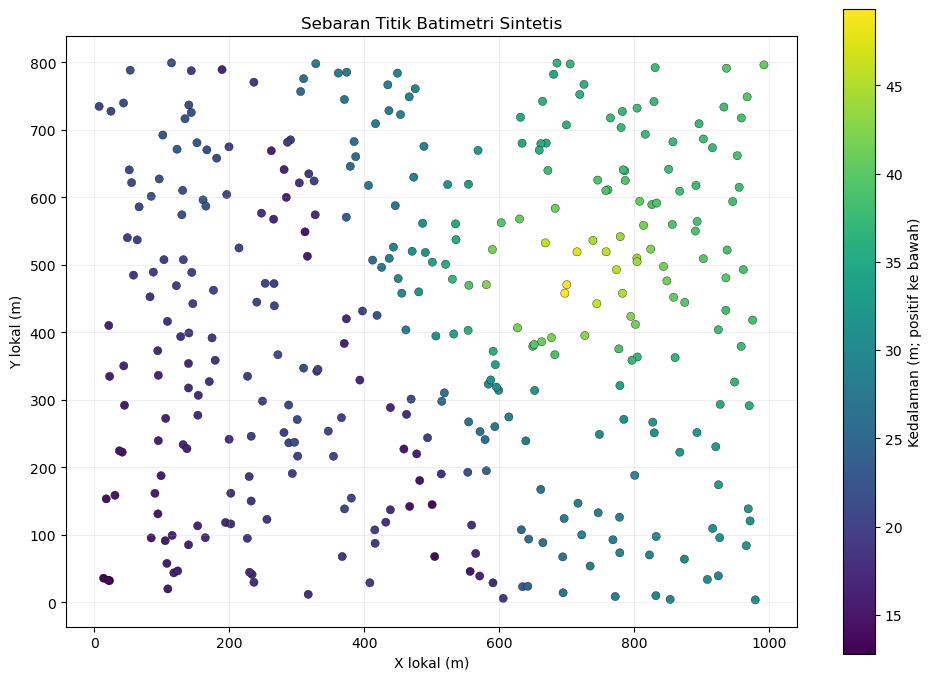

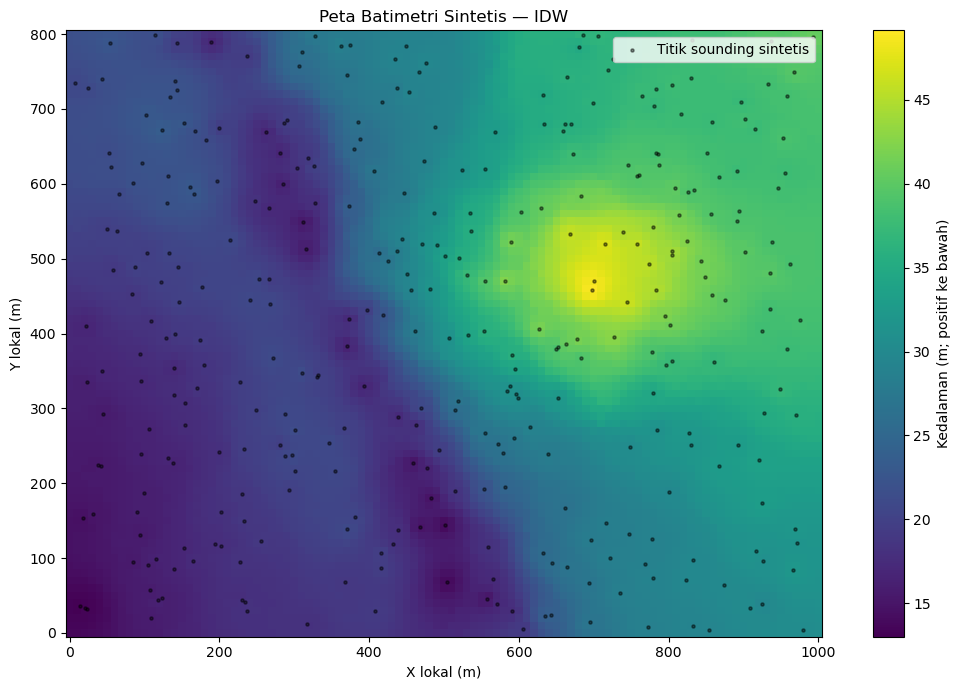

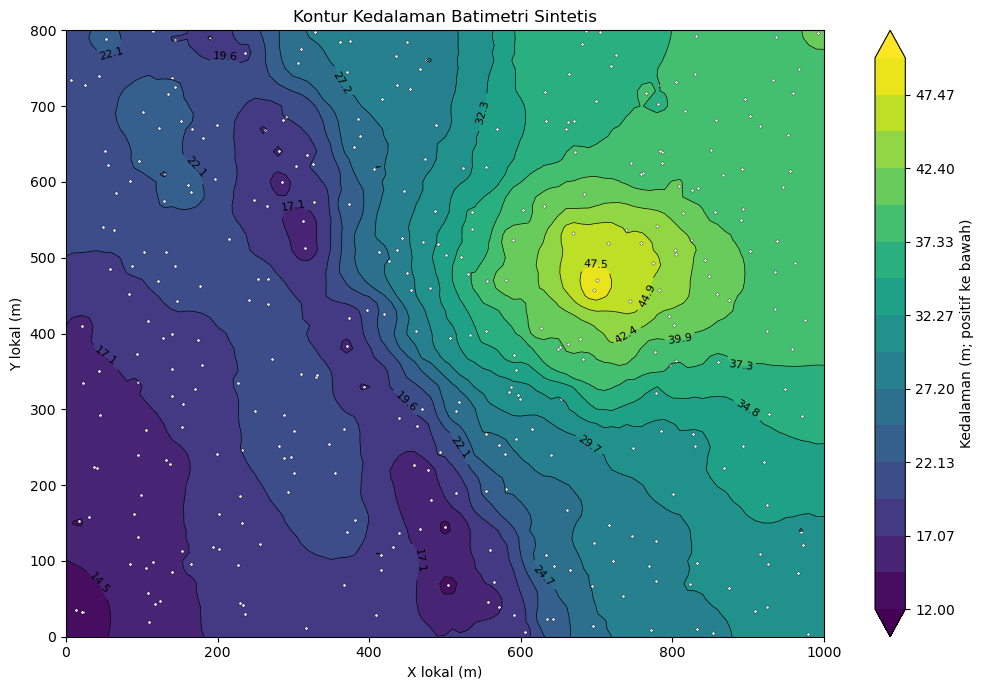

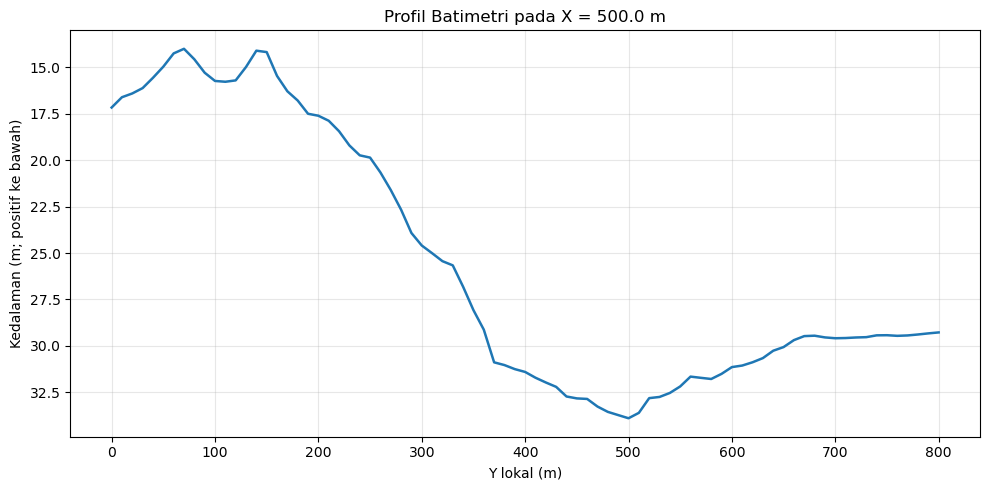


=== VALIDASI SILANG IDW ===
    Metric      Value
N_validasi 350.000000
    RMSE_m   0.976113
     MAE_m   0.694162
    Bias_m   0.047404


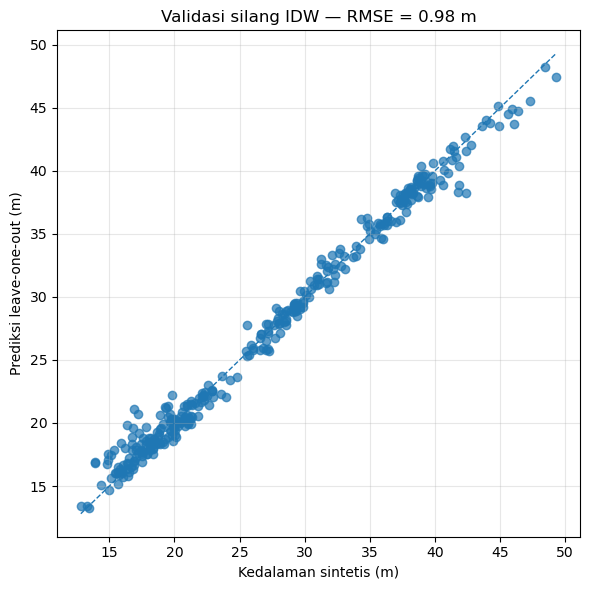


=== RINGKASAN DATA BATIMETRI SINTETIS ===
Jumlah titik: 350
Kedalaman titik minimum: 12.81 m
Kedalaman titik maksimum: 49.31 m
Kedalaman titik rata-rata: 27.43 m
Kedalaman grid minimum: 12.99 m
Kedalaman grid maksimum: 49.15 m
Resolusi grid: 10.0 m
Jumlah sel grid: 8181
Jumlah sel grid kosong: 0

Semua hasil tersimpan di:
D:\KULIAH\SEMESTER 6\AI\hasil_simulasi_batimetri

PERINGATAN: seluruh koordinat, kedalaman, dan morfologi dalam analisis ini adalah sintetis. Jangan gunakan sebagai peta navigasi, peta hidrografi resmi, atau interpretasi lokasi nyata.


In [19]:

# ============================================================
# PRAKTIKUM GEOFISIKA KELAUTAN
# SIMULASI PENGOLAHAN DATA BATIMETRI
#
# SELURUH DATA BERSIFAT SINTETIS, BUKAN DATA SURVEI NYATA.
#
# Output:
# 1. Data titik sintetis
# 2. Quality control (QC)
# 3. Peta sebaran titik kedalaman
# 4. Peta batimetri hasil interpolasi IDW
# 5. Peta kontur kedalaman
# 6. Profil penampang batimetri
# 7. Evaluasi interpolasi dengan validasi silang
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.spatial import cKDTree

# ============================================================
# 1. PARAMETER SIMULASI
# ============================================================

SEED = 42
rng = np.random.default_rng(SEED)

OUTPUT = Path("hasil_simulasi_batimetri")
OUTPUT.mkdir(exist_ok=True, parents=True)

# Domain koordinat lokal (meter)
X_MIN, X_MAX = 0.0, 1000.0
Y_MIN, Y_MAX = 0.0, 800.0

# Jumlah titik sounding sintetis
N_POINTS = 350

# Resolusi grid interpolasi
GRID_SPACING = 10.0

# Parameter IDW
IDW_POWER = 2.0
MAX_NEIGHBORS = 12
MAX_DISTANCE = 180.0  # meter; di luar jarak ini grid dibiarkan kosong

# ============================================================
# 2. MEMBANGUN MODEL DASAR LAUT SINTETIS
# ============================================================

def synthetic_bathymetry(x, y):
    """
    Menghasilkan kedalaman positif ke bawah (meter).

    Bentuk sintetis:
    - lereng regional
    - cekungan
    - punggungan
    - undulasi kecil
    """

    x = np.asarray(x)
    y = np.asarray(y)

    # Kedalaman regional meningkat ke arah timur laut
    regional_slope = 12 + 0.020*x + 0.012*y

    # Cekungan berbentuk elips
    basin = 18 * np.exp(
        -(
            ((x - 680) / 170)**2
            + ((y - 470) / 130)**2
        )
    )

    # Punggungan memanjang dengan sumbu utama miring
    ridge_coordinate = (
        (x - 400) * np.cos(np.deg2rad(25))
        + (y - 350) * np.sin(np.deg2rad(25))
    )

    ridge = -9 * np.exp(
        -(ridge_coordinate / 65)**2
    )

    # Undulasi berskala pendek
    undulation = (
        1.2 * np.sin(x / 90)
        * np.cos(y / 110)
    )

    return regional_slope + basin + ridge + undulation


# ============================================================
# 3. MEMBUAT TITIK SOUNDING SINTETIS
# ============================================================

x_obs = rng.uniform(X_MIN, X_MAX, N_POINTS)
y_obs = rng.uniform(Y_MIN, Y_MAX, N_POINTS)

# Kedalaman model + noise pengukuran sintetis
z_true = synthetic_bathymetry(x_obs, y_obs)
z_obs = z_true + rng.normal(0, 0.35, N_POINTS)

df = pd.DataFrame({
    "X_m": x_obs,
    "Y_m": y_obs,
    "Depth_m": z_obs
})

# Seluruh titik merupakan data simulasi
df["Data_type"] = "SYNTHETIC"

# Simpan data mentah sintetis
df.to_csv(
    OUTPUT / "01_data_batimetri_sintetis.csv",
    index=False
)

print("Jumlah titik sintetis:", len(df))
print(df.head())

# ============================================================
# 4. QUALITY CONTROL
# ============================================================

qc_rows = []

for col in ["X_m", "Y_m", "Depth_m"]:
    qc_rows.append({
        "Parameter": col,
        "Jumlah_data": int(df[col].notna().sum()),
        "Jumlah_kosong": int(df[col].isna().sum()),
        "Minimum": float(df[col].min()),
        "Median": float(df[col].median()),
        "Maksimum": float(df[col].max())
    })

qc = pd.DataFrame(qc_rows)

print("\n=== QUALITY CONTROL ===")
print(qc.to_string(index=False))

qc.to_csv(OUTPUT / "02_quality_control.csv", index=False)

# Pemeriksaan nilai tidak valid
invalid = (
    df[["X_m", "Y_m", "Depth_m"]].isna().any(axis=1)
    | ~np.isfinite(df[["X_m", "Y_m", "Depth_m"]]).all(axis=1)
)

print("\nJumlah baris tidak valid:", int(invalid.sum()))

# Buang baris tidak valid
df = df.loc[~invalid].copy()

# Periksa domain koordinat
outside = (
    (df["X_m"] < X_MIN) | (df["X_m"] > X_MAX)
    | (df["Y_m"] < Y_MIN) | (df["Y_m"] > Y_MAX)
)

print("Jumlah titik di luar domain:", int(outside.sum()))

# Pemeriksaan duplikasi posisi
duplicate_positions = df.duplicated(
    subset=["X_m", "Y_m"],
    keep=False
)

print(
    "Jumlah baris dengan posisi duplikat:",
    int(duplicate_positions.sum())
)

# ============================================================
# 5. VISUALISASI TITIK PENGUKURAN
# ============================================================

fig, ax = plt.subplots(figsize=(10, 7))

sc = ax.scatter(
    df["X_m"],
    df["Y_m"],
    c=df["Depth_m"],
    s=35,
    edgecolor="black",
    linewidth=0.25
)

cb = fig.colorbar(sc, ax=ax)
cb.set_label("Kedalaman (m; positif ke bawah)")

ax.set_xlabel("X lokal (m)")
ax.set_ylabel("Y lokal (m)")
ax.set_title("Sebaran Titik Batimetri Sintetis")
ax.set_aspect("equal")
ax.grid(alpha=0.2)

fig.tight_layout()
fig.savefig(OUTPUT / "03_sebaran_titik.png", dpi=300)
plt.show()

# ============================================================
# 6. INTERPOLASI IDW
# ============================================================

x_grid = np.arange(X_MIN, X_MAX + GRID_SPACING, GRID_SPACING)
y_grid = np.arange(Y_MIN, Y_MAX + GRID_SPACING, GRID_SPACING)

XX, YY = np.meshgrid(x_grid, y_grid)

xy = df[["X_m", "Y_m"]].to_numpy()
depth = df["Depth_m"].to_numpy()

tree = cKDTree(xy)

grid_points = np.column_stack([
    XX.ravel(),
    YY.ravel()
])

distances, indices = tree.query(
    grid_points,
    k=min(MAX_NEIGHBORS, len(df))
)

# Bentuk matriks 2D agar k=1 tetap bisa ditangani
if distances.ndim == 1:
    distances = distances[:, None]
    indices = indices[:, None]

# IDW
weights = 1.0 / np.maximum(distances, 1e-10)**IDW_POWER

neighbor_depths = depth[indices]

z_grid = np.sum(
    weights * neighbor_depths,
    axis=1
) / np.sum(weights, axis=1)

# Masking: hindari ekstrapolasi jauh dari titik pengukuran
nearest_distance = distances[:, 0]
z_grid[nearest_distance > MAX_DISTANCE] = np.nan

ZZ = z_grid.reshape(XX.shape)

grid_df = pd.DataFrame({
    "X_m": XX.ravel(),
    "Y_m": YY.ravel(),
    "Depth_IDW_m": ZZ.ravel()
})

grid_df.to_csv(
    OUTPUT / "04_grid_batimetri_IDW.csv",
    index=False
)

# ============================================================
# 7. PETA BATIMETRI
# ============================================================

fig, ax = plt.subplots(figsize=(11, 7))

mesh = ax.pcolormesh(
    XX,
    YY,
    ZZ,
    shading="auto"
)

cb = fig.colorbar(mesh, ax=ax)
cb.set_label("Kedalaman (m; positif ke bawah)")

ax.scatter(
    df["X_m"],
    df["Y_m"],
    s=5,
    c="black",
    alpha=0.45,
    label="Titik sounding sintetis"
)

ax.set_xlabel("X lokal (m)")
ax.set_ylabel("Y lokal (m)")
ax.set_title("Peta Batimetri Sintetis — IDW")
ax.set_aspect("equal")
ax.legend()

fig.tight_layout()
fig.savefig(OUTPUT / "05_peta_batimetri_IDW.png", dpi=300)
plt.show()

# ============================================================
# 8. PETA KONTUR KEDALAMAN
# ============================================================

valid_depths = ZZ[np.isfinite(ZZ)]

levels = np.linspace(
    np.floor(valid_depths.min()),
    np.ceil(valid_depths.max()),
    16
)

fig, ax = plt.subplots(figsize=(11, 7))

filled = ax.contourf(
    XX, YY, ZZ,
    levels=levels,
    extend="both"
)

lines = ax.contour(
    XX, YY, ZZ,
    levels=levels,
    colors="black",
    linewidths=0.5
)

ax.clabel(lines, inline=True, fontsize=8, fmt="%.1f")

cb = fig.colorbar(filled, ax=ax)
cb.set_label("Kedalaman (m; positif ke bawah)")

ax.scatter(
    df["X_m"],
    df["Y_m"],
    s=5,
    c="white",
    edgecolor="black",
    linewidth=0.25
)

ax.set_xlabel("X lokal (m)")
ax.set_ylabel("Y lokal (m)")
ax.set_title("Kontur Kedalaman Batimetri Sintetis")
ax.set_aspect("equal")

fig.tight_layout()
fig.savefig(OUTPUT / "06_kontur_batimetri.png", dpi=300)
plt.show()

# ============================================================
# 9. PROFIL PENAMPANG BATIMETRI
# ============================================================

# Profil sepanjang Y pada X yang ditentukan
X_PROFILE = 500.0

j = np.argmin(np.abs(x_grid - X_PROFILE))
profile_depth = ZZ[:, j]

profile_df = pd.DataFrame({
    "Y_m": y_grid,
    "Depth_IDW_m": profile_depth
})

profile_df.to_csv(
    OUTPUT / "07_profil_batimetri.csv",
    index=False
)

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    y_grid,
    profile_depth,
    linewidth=1.8
)

ax.set_xlabel("Y lokal (m)")
ax.set_ylabel("Kedalaman (m; positif ke bawah)")
ax.set_title(f"Profil Batimetri pada X = {x_grid[j]:.1f} m")
ax.invert_yaxis()
ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig(OUTPUT / "08_profil_penampang.png", dpi=300)
plt.show()

# ============================================================
# 10. VALIDASI SILANG LEAVE-ONE-OUT UNTUK IDW
# ============================================================

# Prediksi setiap titik dengan tetangga lain,
# tanpa menggunakan nilai kedalaman titik itu sendiri.
# Ini menguji interpolasi pada titik ukur, tetapi bukan
# validasi independen terhadap survei eksternal.

k_cv = min(MAX_NEIGHBORS + 1, len(df))

dist_cv, idx_cv = tree.query(
    xy,
    k=k_cv
)

if dist_cv.ndim == 1:
    dist_cv = dist_cv[:, None]
    idx_cv = idx_cv[:, None]

pred_cv = np.full(len(df), np.nan)

for i in range(len(df)):
    # Hilangkan indeks titik itu sendiri
    keep = idx_cv[i] != i

    d = dist_cv[i][keep]
    ix = idx_cv[i][keep]

    # Batasi jumlah tetangga yang digunakan
    d = d[:MAX_NEIGHBORS]
    ix = ix[:MAX_NEIGHBORS]

    # Jangan memprediksi jika tidak ada tetangga memadai
    if len(ix) == 0:
        continue

    if np.min(d) > MAX_DISTANCE:
        continue

    w = 1.0 / np.maximum(d, 1e-10)**IDW_POWER
    pred_cv[i] = np.sum(w * depth[ix]) / np.sum(w)

valid_cv = np.isfinite(pred_cv)

if valid_cv.sum() > 0:
    observed = depth[valid_cv]
    predicted = pred_cv[valid_cv]
    errors = predicted - observed

    rmse = np.sqrt(np.mean(errors**2))
    mae = np.mean(np.abs(errors))
    bias = np.mean(errors)

    metrics = pd.DataFrame({
        "Metric": ["N_validasi", "RMSE_m", "MAE_m", "Bias_m"],
        "Value": [int(valid_cv.sum()), rmse, mae, bias]
    })

    print("\n=== VALIDASI SILANG IDW ===")
    print(metrics.to_string(index=False))

    metrics.to_csv(
        OUTPUT / "09_validasi_silang.csv",
        index=False
    )

    fig, ax = plt.subplots(figsize=(6, 6))
    ax.scatter(observed, predicted, alpha=0.7)

    low = min(observed.min(), predicted.min())
    high = max(observed.max(), predicted.max())

    ax.plot([low, high], [low, high], "--", linewidth=1)
    ax.set_xlabel("Kedalaman sintetis (m)")
    ax.set_ylabel("Prediksi leave-one-out (m)")
    ax.set_title(f"Validasi silang IDW — RMSE = {rmse:.2f} m")
    ax.grid(alpha=0.3)

    fig.tight_layout()
    fig.savefig(OUTPUT / "10_validasi_IDW.png", dpi=300)
    plt.show()

else:
    print("Validasi silang tidak menghasilkan prediksi valid.")

# ============================================================
# 11. RINGKASAN MORFOLOGI BERDASARKAN GRID
# ============================================================

print("\n=== RINGKASAN DATA BATIMETRI SINTETIS ===")
print(f"Jumlah titik: {len(df)}")
print(f"Kedalaman titik minimum: {df['Depth_m'].min():.2f} m")
print(f"Kedalaman titik maksimum: {df['Depth_m'].max():.2f} m")
print(f"Kedalaman titik rata-rata: {df['Depth_m'].mean():.2f} m")
print(f"Kedalaman grid minimum: {np.nanmin(ZZ):.2f} m")
print(f"Kedalaman grid maksimum: {np.nanmax(ZZ):.2f} m")
print(f"Resolusi grid: {GRID_SPACING:.1f} m")
print(f"Jumlah sel grid: {ZZ.size}")
print(f"Jumlah sel grid kosong: {np.isnan(ZZ).sum()}")

print("\nSemua hasil tersimpan di:")
print(OUTPUT.resolve())

print(
    "\nPERINGATAN: seluruh koordinat, kedalaman, dan morfologi "
    "dalam analisis ini adalah sintetis. Jangan gunakan sebagai "
    "peta navigasi, peta hidrografi resmi, atau interpretasi "
    "lokasi nyata."
)


**Interpretasi singkat**

**1. Sebaran titik batimetri sintetis**

Titik sounding tersebar pada area sekitar 0–1.000 m pada sumbu X dan 0–800 m pada sumbu Y. Kedalaman berkisar sekitar 12–49 m, dengan kecenderungan kedalaman lebih besar di bagian timur dan timur-tengah area. Sebaran titik yang cukup luas mendukung interpolasi, meskipun kerapatan titik yang tidak seragam dapat memengaruhi ketelitian hasil.

**2. Peta batimetri metode IDW**

Peta IDW memperlihatkan zona relatif dangkal di bagian barat dan barat daya, sedangkan zona lebih dalam berada di bagian timur-tengah, dengan kedalaman maksimum sekitar 47–49 m. Pola ini menunjukkan variasi topografi dasar perairan. Nilai di antara titik sounding merupakan hasil estimasi interpolasi, bukan pengukuran langsung.

**3. Peta kontur batimetri**

Kontur memperlihatkan perubahan kedalaman yang cukup tajam di bagian tengah, terutama sekitar X = 500–650 m. Kontur yang rapat mengindikasikan perubahan kedalaman yang lebih besar dalam jarak relatif pendek. Zona terdalam terpusat di sekitar X = 700–750 m dan Y = 450–520 m.

**4. Profil batimetri pada X = 500 m**

Profil menunjukkan kedalaman sekitar 17 m pada bagian awal, kemudian bertambah secara bertahap hingga mencapai sekitar 34 m pada Y = 500 m. Setelah itu, dasar perairan kembali relatif dangkal menuju sekitar 29–30 m di ujung profil. Hal ini memperlihatkan adanya cekungan relatif pada bagian tengah lintasan.

**5. Validasi silang IDW**

Grafik validasi silang menunjukkan nilai RMSE sebesar 0,98 m. Sebagian besar titik prediksi berada dekat garis kesesuaian, sehingga hasil interpolasi pada data sintetis ini memiliki kesalahan prediksi yang relatif kecil. Namun, RMSE perlu dibandingkan dengan rentang kedalaman dan diuji menggunakan data independen untuk memastikan kemampuan prediksi pada kondisi nyata.

**2. Evaluasi kualitas hasil**

- Kualitas visual: Baik. Peta interpolasi dan kontur mampu memperlihatkan variasi kedalaman dengan jelas.
- Sebaran data: Cukup luas, tetapi ketidakseragaman kerapatan titik berpotensi memengaruhi hasil di area yang jarang memiliki titik pengukuran.
- Hasil interpolasi: Pola kedalaman terlihat konsisten secara visual dengan sebaran titik sounding, tetapi artefak lokal masih mungkin muncul akibat karakteristik IDW.
- Validasi: RMSE 0,98 m merupakan hasil yang menjanjikan untuk data sintetis. Akan tetapi, jika validasi silang menggunakan data yang dibuat dari pola sintetis yang sama, nilai tersebut belum membuktikan akurasi pada batimetri aktual.

**Kesimpulan**

Hasil interpolasi IDW berhasil menggambarkan variasi kedalaman dasar perairan, dengan zona dangkal di bagian barat dan zona lebih dalam di bagian timur-tengah. Peta kontur dan profil penampang memperlihatkan perubahan kedalaman yang cukup jelas, termasuk cekungan relatif di sekitar lintasan X = 500 m. Nilai RMSE 0,98 m menunjukkan kesesuaian prediksi yang baik terhadap data uji sintetis. Meski demikian, evaluasi lebih lanjut menggunakan data batimetri lapangan dan pembandingan dengan metode interpolasi lain diperlukan sebelum hasil diterapkan untuk pemetaan dasar perairan yang sebenarnya.